# Interpretable Carbon-Aware Electricity Pricing — implementation notebook

MIT 15.095 · Clement Docteur & Panle Chen · Low Carbon London 2013 dynamic time-of-use (TOU) trial

This notebook **is** the ML pipeline, written out step by step in executable cells: data preprocessing, carbon-intensity
forecasting, demand-response estimation, tariff optimisation, Optimal Policy Trees, budget-aware trees and household-bill
constraints. Every function is defined in the notebook (transcribed from the project's `.py` modules with the same
specifications, seeds and constraints), every model is trained here, and every intermediate object (`DataFrame`, array,
tree) stays in memory so you can inspect, modify and re-run any step.

**Faithfulness.** Each stage ends with a `check(...)` cell that compares the notebook's result with the saved output of the
project pipeline (`run_mvp.py`). A mismatch stops the notebook.

**Two modes** (first code cell, or environment variable `PROJECT_NOTEBOOK_MODE=full`):

| | Review (default) | Full |
|---|---|---|
| Preprocessing (selection, gap filling, aggregation, features) | run | run |
| Demand model, menu, exact policy trees, budget-aware and bill-penalised trees | trained live for the **Nov–Dec** window | trained live for **all four** rolling windows |
| Carbon forecaster | refits the selected model for Nov and Dec; earlier months' out-of-sample forecasts are loaded from the pipeline | full hyper-parameter search + 12 monthly refits of all four models |
| IAI Optimal Policy Trees (Julia) | reads the pipeline's saved IAI fits and runs the selection / evaluation here | refits with IAI (Julia) in a temporary folder |
| Raw 8.5 GB csv → household matrix | uses the pipeline's matrix | also rebuilds it in a temporary folder and compares |
| Runtime | ≈ 2 min | ≈ 10–15 min |

Nothing is written to the repository in either mode (Full mode uses temporary folders); the last cell verifies this.

**Kept outside the notebook (and why).** (i) The one-pass DuckDB conversion of the 8.5 GB raw csv
(`CVAE_reproduction/scripts/01_build_lcl2013.py`) — data engineering with dozens of bookkeeping statistics; the notebook
re-implements and runs the *modelling* part of preprocessing (household selection, gap filling, aggregation) on its output.
(ii) Clement's behavioural clustering (NMF + k-medoids, `CVAE_reproduction/scripts/04_clustering.py`) and ERA5 temperature
interpolation (`03_conditions.py`) — upstream artefacts loaded as data. (iii) The IAI solver itself, which runs in Julia
(`carbon_tariff_pipeline/scripts/07_iai_fit.jl`); data export, selection and evaluation are notebook code.
(iv) The CVAE (not retrained; only a sensitivity world in the report).

**Provenance.** 🟦 Clement's original method (reproduced) · 🟩 added in the MVP · 🟨 retrospective (hindsight; not
deployable). All effects are **model-based estimates**; primary metric = realised **average** carbon intensity,
reduction (%) = 100 × (E_TOU − E_policy) / E_TOU.

## 0. Setup

In [1]:
import os
MODE = os.environ.get("PROJECT_NOTEBOOK_MODE", "review").strip().lower()     # "review" or "full"
assert MODE in ("review", "full"); FULL = MODE == "full"
print("MODE =", MODE)

MODE = review


In [2]:
%matplotlib inline
import hashlib, json, shutil, subprocess, sys, tempfile, time, warnings
from collections import Counter
from pathlib import Path

import duckdb
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import Image, Markdown, display
from scipy.stats import spearmanr
from sklearn.ensemble import RandomForestRegressor
from sklearn.linear_model import Lasso, Ridge
from sklearn.preprocessing import StandardScaler
from xgboost import XGBRegressor

ROOT = (Path(os.environ["PROJECT_ROOT"]) if "PROJECT_ROOT" in os.environ
        else next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "run_mvp.py").exists()))
RAW_DIRS = ([Path(os.environ["CARBON_RAW_DIR"])] if os.environ.get("CARBON_RAW_DIR") else []) + [ROOT, ROOT.parent]
def raw_file(*names):
    # raw data (read only): $CARBON_RAW_DIR, then the repository root, then the folder containing the repository
    return next((d / n for d in RAW_DIRS for n in names if (d / n).exists()), RAW_DIRS[0] / names[0])
DATA = ROOT / "CVAE_reproduction" / "data"                           # Clement's processed data
RES = ROOT / "results"; MVP = RES / "mvp" / "outputs"                # saved pipeline outputs (for checks)
pd.set_option("display.precision", 4); pd.set_option("display.max_columns", 30)

def load_json(p):
    return json.loads(Path(p).read_text(encoding="utf-8"))

def check(name, got, want, tol=1e-9):
    # compare a notebook result with the saved pipeline output; stop on any mismatch
    if isinstance(want, (float, np.floating)) or isinstance(got, (float, np.floating)):
        ok = abs(float(got) - float(want)) <= tol; detail = f"{float(got):.6g} vs saved {float(want):.6g}"
    else:
        ok = got == want; detail = "identical" if ok else f"{got} vs saved {want}"
    print(f"[{'MATCH' if ok else 'MISMATCH'}] {name}: {detail}")
    assert ok, name

def repo_hashes():
    keep = [p for d in (RES, ROOT / "carbon_tariff_pipeline" / "outputs", DATA) for p in d.rglob("*")
            if p.is_file() and "logs" not in p.parts and "_scratch" not in p.parts]
    keep += [ROOT / "project_walkthrough.ipynb"]
    return {str(p.relative_to(ROOT)): (p.stat().st_size, p.stat().st_mtime_ns) for p in keep}

T0, BEFORE = time.time(), repo_hashes()
JULIA = shutil.which("julia") is not None
WINDOWS = (5, 7, 9, 11) if FULL else (11,)                          # rolling test windows trained live (first month)
SAVED = {"step1": load_json(MVP / "step1_metrics.json"), "step2": load_json(MVP / "step2_results.json"),
         "step3": load_json(MVP / "step3_results_average_mvp.json"), "iai": load_json(MVP / "iai_opt_results_average_mvp.json"),
         "pacing": load_json(RES / "pacing" / "pacing_results.json"), "aff": load_json(RES / "affordability" / "affordability_results.json")}
print(f"repository {ROOT.name} | windows trained live: {WINDOWS} | Julia/IAI: {JULIA}")

repository dynamic_pricing_to_reduce_co2 | windows trained live: (11,) | Julia/IAI: True


## 1. Data loading & preprocessing 🟦

### 1.1 Conventions
2013 has 365 days × 48 half-hours. **Slot *h* of date *d* is the half-hour ending at *d* + 30·*h* min GMT** (slot 0 =
23:30–24:00 of the previous day). LCL timestamps are GMT (no DST gaps); NESO rows are UTC and start-labelled, so the CI of
slot *h* is the NESO row at *d* + 30·(*h*−1) min. Prices: Low 3.99, Normal 11.76, High 67.20 p/kWh; flat tariff 14.228.

In [3]:
H = 48
PRICE = {"L": 3.99, "N": 11.76, "H": 67.20}                 # p/kWh
FLAT_PRICE = 14.228
SPLIT = {"train": ("2013-01-01", "2013-08-31"), "val": ("2013-09-01", "2013-10-31"), "test": ("2013-11-01", "2013-12-31")}
DATES_2013 = pd.date_range("2013-01-01", "2013-12-31", freq="D")
ALL = np.arange(365)
BANK_HOLIDAYS = pd.to_datetime([                             # England & Wales, 2009-2014 (gov.uk)
    "2009-01-01", "2009-04-10", "2009-04-13", "2009-05-04", "2009-05-25", "2009-08-31", "2009-12-25", "2009-12-28",
    "2010-01-01", "2010-04-02", "2010-04-05", "2010-05-03", "2010-05-31", "2010-08-30", "2010-12-27", "2010-12-28",
    "2011-01-03", "2011-04-22", "2011-04-25", "2011-04-29", "2011-05-02", "2011-05-30", "2011-08-29", "2011-12-26",
    "2011-12-27", "2012-01-02", "2012-04-06", "2012-04-09", "2012-05-07", "2012-06-04", "2012-06-05", "2012-08-27",
    "2012-12-25", "2012-12-26", "2013-01-01", "2013-03-29", "2013-04-01", "2013-05-06", "2013-05-27", "2013-08-26",
    "2013-12-25", "2013-12-26", "2014-01-01"])

def cols(prefix):
    return [f"{prefix}_{h:02d}" for h in range(H)]

def hours(a, b):
    # slots covering [a:00, b:00) GMT under the end-labelled slot convention
    return slice(2 * a + 1, 2 * b + 1)

def split_of(dates):
    d = pd.to_datetime(pd.Series(dates)).to_numpy(); out = np.full(len(d), "", dtype=object)
    for k, (a, b) in SPLIT.items():
        out[(d >= np.datetime64(a)) & (d <= np.datetime64(b))] = k
    return out

def day_type(dates):
    # 0 = working day, 1 = weekend or bank holiday
    dates = pd.DatetimeIndex(dates)
    return np.asarray((dates.dayofweek >= 5) | dates.isin(BANK_HOLIDAYS)).astype(int)

def read_parquet(path):
    return duckdb.sql(f"select * from read_parquet('{Path(path).as_posix()}')").df()

DAYTYPE = day_type(DATES_2013)
print(pd.Series(split_of(DATES_2013)).value_counts().to_string())

train    243
val       61
test      61


### 1.2 Raw smart-meter data
The raw file has one row per household × half-hour (`LCLid`, `stdorToU`, `DateTime`, `KWH/hh`). Its one-pass conversion
(DuckDB) produces a household table with each household's 2013 completeness and a dense matrix of 2013 readings
(`NaN` = missing). Here we peek at the raw csv and load those two outputs.

In [4]:
raw_csv = raw_file("CC_LCL-FullData.csv", "LCL_Data/CC_LCL-FullData.csv")
display(duckdb.sql(f"SELECT * FROM read_csv('{raw_csv.as_posix()}', header=true, all_varchar=true) LIMIT 5").df())
households = read_parquet(DATA / "lcl2013_households.parquet")           # one row per household in the 2013 window
dense = np.load(DATA / "lcl2013_kwh.npy", mmap_mode="r")                  # (households, 17520) kWh, NaN = missing
print("households with 2013 data:", households.group.value_counts().to_dict(), "| dense matrix", dense.shape)
display(households[["LCLid", "group", "n_valid_2013", "completeness", "n_dup_slots_2013"]].describe(include="all").T.head(6))

,LCLid,stdorToU,DateTime,KWH/hh (per half hour)
0,MAC000002,Std,2012-10-12 00:30:00.0000000,0
1,MAC000002,Std,2012-10-12 01:00:00.0000000,0
2,MAC000002,Std,2012-10-12 01:30:00.0000000,0
3,MAC000002,Std,2012-10-12 02:00:00.0000000,0
4,MAC000002,Std,2012-10-12 02:30:00.0000000,0


households with 2013 data: {'Std': 4411, 'ToU': 1117} | dense matrix (5528, 17520)


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
LCLid,5528,5528,MAC000002,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN
group,5528,2,Std,4411,NaN,NaN,NaN,NaN,NaN,NaN,NaN
n_valid_2013,5528.0,NaN,NaN,NaN,16827.8251,2691.5069,385.0,17514.0,17518.0,17519.0,17520.0
completeness,5528.0,NaN,NaN,NaN,0.9605,0.1536,0.022,0.9997,0.9999,0.9999,1.0
n_dup_slots_2013,5528.0,NaN,NaN,NaN,11.5065,1.8905,0.0,12.0,12.0,12.0,12.0


### 1.3 Household selection
All dynamic-TOU households with **> 95 %** valid 2013 half-hours, plus a seeded random sample (`default_rng(0)`, without
replacement, from the LCLid-sorted pool) of the same number of eligible flat-tariff (Std) households as the control group.

In [5]:
def select_households(hh, threshold=0.95, seed=0):
    tou = hh[(hh["group"] == "ToU") & (hh["completeness"] > threshold)].sort_values("LCLid")
    std = hh[(hh["group"] == "Std") & (hh["completeness"] > threshold)].sort_values("LCLid")
    rng = np.random.default_rng(seed)
    draw = rng.choice(len(std), size=min(len(tou), len(std)), replace=False)
    order = np.argsort(draw)
    std_sel = std.iloc[draw[order]].copy()
    std_sel["std_draw_order"] = order.astype(np.int32)
    tou = tou.copy(); tou["std_draw_order"] = np.int32(-1)
    sel = pd.concat([tou, std_sel], ignore_index=True)
    sel = sel[["LCLid", "group", "completeness", "row", "std_draw_order"]].rename(columns={"row": "row_in_dense"})
    sel.insert(2, "row_in_filled", np.arange(len(sel), dtype=np.int32))
    return sel

selection = select_households(households)
print(selection.group.value_counts().to_dict(), "| eligible Std pool:", int(((households.group == "Std") & (households.completeness > 0.95)).sum()))
saved_sel = read_parquet(DATA / "selection.parquet")
check("selected households (LCLid, group, order)", bool((selection[["LCLid", "group"]].to_numpy() == saved_sel[["LCLid", "group"]].to_numpy()).all()), True)

{'ToU': 1032, 'Std': 1032} | eligible Std pool: 4034
[MATCH] selected households (LCLid, group, order): identical


### 1.4 Gap filling
Rule recovered from the CVAE authors' data: a **single** missing half-hour with observations on both sides is linearly
interpolated in time; every other missing half-hour at (day *d*, slot *h*) is linearly interpolated **across days at the
same half-hour** between the nearest earlier day *p* and later day *q* observed at *h*:
$x_{d,h} = x_{p,h} + (x_{q,h}-x_{p,h})\,\frac{d-p}{q-p}$ (one side only at the year edges).

In [6]:
def fill_gaps(X, short_max=1, chunk=400):
    X = np.asarray(X); n, T = X.shape
    out = np.empty((n, T), dtype=np.float32); n_short = n_long = 0
    idx, days = np.arange(T), np.arange(365)
    for a in range(0, n, chunk):
        x = X[a:a + chunk].astype(np.float64); k = x.shape[0]
        valid = ~np.isnan(x); miss = ~valid
        prev = np.maximum.accumulate(np.where(valid, idx, -1), axis=1)                       # last observed slot
        nxt = np.minimum.accumulate(np.where(valid, idx, T)[:, ::-1], axis=1)[:, ::-1]       # next observed slot
        gap_len = nxt - prev - 1
        short = miss & (prev >= 0) & (nxt < T) & (gap_len <= short_max)
        y = x.copy()
        rr, cc = np.nonzero(short); p, q = prev[rr, cc], nxt[rr, cc]; w = (cc - p) / (q - p)
        y[rr, cc] = x[rr, p] * (1.0 - w) + x[rr, q] * w                                       # linear in time
        n_short += len(rr)
        longm = miss & ~short
        if longm.any():
            xd, vd = x.reshape(k, 365, H), valid.reshape(k, 365, H)
            pdy = np.maximum.accumulate(np.where(vd, days[None, :, None], -1), axis=1)       # previous observed day, same slot
            ndy = np.minimum.accumulate(np.where(vd, days[None, :, None], 365)[:, ::-1, :], axis=1)[:, ::-1, :]
            li, ld, lh = np.nonzero(longm.reshape(k, 365, H))
            p_d, n_d = pdy[li, ld, lh], ndy[li, ld, lh]
            vp = np.where(p_d >= 0, xd[li, np.clip(p_d, 0, 364), lh], np.nan)
            vn = np.where(n_d < 365, xd[li, np.clip(n_d, 0, 364), lh], np.nan)
            both = np.vstack([vp, vn]); cnt_ = (~np.isnan(both)).sum(axis=0)
            fill = np.where(cnt_ > 0, np.nansum(both, axis=0) / np.maximum(cnt_, 1), np.nan)
            two = cnt_ == 2
            fill[two] = vp[two] + (vn[two] - vp[two]) * (ld[two] - p_d[two]) / (n_d[two] - p_d[two])   # linear across days
            y.reshape(k, 365, H)[li, ld, lh] = fill
            n_long += len(li)
        out[a:a + k] = y.astype(np.float32)
    return out, {"filled_short_linear": n_short, "filled_long_sameslot_days": n_long}

X_sel = np.asarray(dense[selection.row_in_dense.to_numpy()])
kwh_filled, fill_stats = fill_gaps(X_sel)
print(fill_stats, f"| missing share {np.isnan(X_sel).mean():.4%} | NaN left: {int(np.isnan(kwh_filled).sum())}")
check("gap-filled matrix identical to the pipeline's lcl2013_kwh_filled.npy",
      bool(np.array_equal(kwh_filled, np.load(DATA / "lcl2013_kwh_filled.npy"))), True)

{'filled_short_linear': 3328, 'filled_long_sameslot_days': 19128} | missing share 0.0621% | NaN left: 0
[MATCH] gap-filled matrix identical to the pipeline's lcl2013_kwh_filled.npy: identical


In [7]:
# Full mode only: rebuild the dense matrix from the raw csv with Clement's DuckDB build script (temporary folder)
if FULL:
    with tempfile.TemporaryDirectory(prefix="lcl_build_") as tmp:
        r = subprocess.run([sys.executable, "-P", "scripts/01_build_lcl2013.py", "--threads", "8", "--data-dir", tmp, "--work", tmp],
                           cwd=ROOT / "CVAE_reproduction", capture_output=True, text=True)
        print(r.stdout[-1200:]); assert r.returncode == 0, r.stderr[-2000:]
        check("raw-csv rebuild == dense matrix used above", bool(np.array_equal(np.load(Path(tmp) / "lcl2013_kwh.npy"), np.asarray(dense), equal_nan=True)), True)
else:
    print("[review] raw-csv rebuild skipped (Full mode runs it)")

[review] raw-csv rebuild skipped (Full mode runs it)


### 1.5 Household panel, clusters and aggregation
Each household's 2013 series is reshaped to (365 days × 48 slots). The 1,032 TOU households carry Clement's 4 behavioural
clusters (NMF + k-medoids, relabelled to the paper's numbering). The demand model works on **cluster-mean** consumption
$\bar y_{c,d,h}$; the flat-tariff mean $\bar y^{Std}_{d,h}$ is the control series; $w_c$ = cluster share of households.

cluster sizes [285, 299, 299, 149] | weights [0.276, 0.29, 0.29, 0.144]
[MATCH] cluster means vs Clement's power_consump_ours.parquet (max abs diff, kWh): 3.60513e-07 vs saved 0


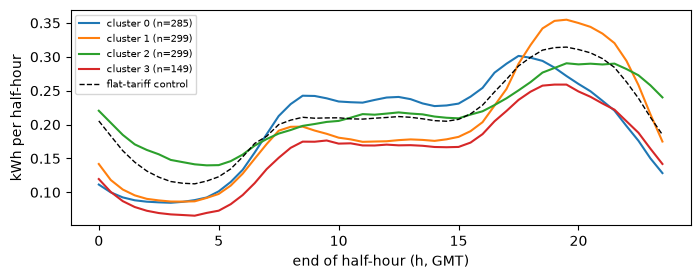

In [8]:
clusters = read_parquet(DATA / "clusters_run_a.parquet")
tou_rows = clusters[clusters.group == "ToU"].sort_values("row_in_filled")
std_rows = clusters[clusters.group == "Std"].sort_values("row_in_filled").row_in_filled.to_numpy()
CL = tou_rows["nmf"].map({0: 2, 1: 0, 2: 1, 3: 3}).to_numpy(int)              # paper's cluster labels
Y_tou = kwh_filled[tou_rows.row_in_filled.to_numpy()].reshape(-1, 365, H)     # (1032, 365, 48)
Y_std = kwh_filled[std_rows].reshape(-1, 365, H)
SIZES = np.bincount(CL); W = SIZES / SIZES.sum()
YC = np.stack([Y_tou[CL == c].mean(0) for c in range(4)]).astype(float)       # (4, 365, 48) cluster means
YALL = np.einsum("c,cdh->dh", W, YC)                                          # household-mean TOU consumption
STD_MEAN = Y_std.mean(0).astype(float)
print("cluster sizes", SIZES.tolist(), "| weights", W.round(3).tolist())
pc = read_parquet(DATA / "power_consump_ours.parquet")
check("cluster means vs Clement's power_consump_ours.parquet (max abs diff, kWh)",
      max(float(np.abs(pc[pc.cluster == c].sort_values("date")[cols("consumption")].to_numpy(float) - YC[c]).max()) for c in range(4)), 0.0, tol=1e-6)
fig, ax = plt.subplots(figsize=(8, 2.8))
for c in range(4):
    ax.plot(np.arange(H) / 2, YC[c].mean(0), label=f"cluster {c} (n={SIZES[c]})")
ax.plot(np.arange(H) / 2, STD_MEAN.mean(0), "k--", lw=1, label="flat-tariff control"); ax.legend(fontsize=7)
ax.set_xlabel("end of half-hour (h, GMT)"); ax.set_ylabel("kWh per half-hour"); plt.show()

### 1.6 Tariff schedule, temperature and carbon intensity
The historical schedule is the CVAE authors' slot-aligned 2013 version (validated by an event study; `Tariffs.xlsx` is in
London clock time). Temperature is ERA5 2 m temperature at central London (realised reanalysis). CI is NESO's half-hourly
average carbon intensity (g/kWh).

In [9]:
conditions = read_parquet(DATA / "conditions_ours.parquet").sort_values("date").reset_index(drop=True)
LOW_H = conditions[cols("low_auth")].to_numpy(float)                          # (365, 48) 0/1
HIGH_H = conditions[cols("high_auth")].to_numpy(float)

def schedule_price(low, high):
    return np.where(high > 0, PRICE["H"], np.where(low > 0, PRICE["L"], PRICE["N"]))

def price_paid(price, y, axis=None):
    return (price * y).sum(axis) / y.sum(axis)                                 # consumption-weighted price = bill / kWh

PRICE_H = schedule_price(LOW_H, HIGH_H)
TEMP = conditions[cols("temp")].to_numpy(float)                              # degC, slot convention

neso = pd.read_csv(raw_file("df_fuel_ckan.csv"), parse_dates=["DATETIME"]).sort_values("DATETIME").set_index("DATETIME").loc[:"2014-01-02"]

def day_matrix(series, dates):
    # (n_days, 48): slot h of date d = series at d + (h-1)*30 min (NESO start label)
    dates = pd.DatetimeIndex(dates)
    idx = (dates.values[:, None] + (np.arange(H)[None, :] - 1) * np.timedelta64(30, "m")).ravel()
    return series.reindex(idx).to_numpy(float).reshape(len(dates), H)

CI = day_matrix(neso.CARBON_INTENSITY.astype(float), DATES_2013)            # realised CI, (365, 48)
print(f"historical time-average announced price 2013: {PRICE_H.mean():.3f} p/kWh | CI 2013 mean {CI.mean():.1f} g/kWh, NaN {int(np.isnan(CI).sum())}")
check("realised CI equals the pipeline's", float(np.abs(CI - np.load(MVP / "ci_forecasts_2013.npz")["actual"]).max()), 0.0)
display(pd.DataFrame({k: {"days": int((split_of(DATES_2013) == k).sum()), "High-event days": int(HIGH_H[split_of(DATES_2013) == k].any(1).sum()),
                          "Low-event days": int(LOW_H[split_of(DATES_2013) == k].any(1).sum()),
                          "time-average price": PRICE_H[split_of(DATES_2013) == k].mean()} for k in SPLIT}).T)

historical time-average announced price 2013: 13.472 p/kWh | CI 2013 mean 475.0 g/kWh, NaN 0
[MATCH] realised CI equals the pipeline's: 0 vs saved 0


,days,High-event days,Low-event days,time-average price
train,243.0,53.0,61.0,13.6295
val,61.0,13.0,14.0,13.5205
test,61.0,7.0,18.0,12.7954


## 2. Carbon-intensity forecasting 🟦

**Timing.** Day *d*'s tariff is announced at **12:00 GMT on d−1**, so features may use NESO data only up to the half-hour
ending 12:00 on d−1 (horizon 12–36 h). **Target:** each slot's CI minus the *anchor* (mean of the last 24 h known); the
anchor is added back: $\widehat{CI}_{d,h}=\text{anchor}_d+f(x_{d,h})$.

**Features:** anchor, last value, 3-h trend, CI day means 2 and 7 days back, generation-mix shares (coal, gas, wind,
nuclear, imports; last value and 24-h mean), generation level, seasonality, weekday, holidays, and slot-specific lags
(same slot yesterday if known by 12:00, else 2 days back; 7 days back), all lags as deviations from the anchor.

In [10]:
DAYS = pd.date_range("2009-01-09", "2013-12-31", freq="D")
HH30 = np.timedelta64(30, "m")

def build_frame(neso):
    ci, gen = neso.CARBON_INTENSITY.astype(float), neso.GENERATION.astype(float)
    share = lambda cs: neso[cs].sum(axis=1) / gen
    mix = {"coal": share(["COAL"]), "gas": share(["GAS"]), "wind": share(["WIND", "WIND_EMB"]),
           "nuclear": share(["NUCLEAR"]), "imports": share(["IMPORTS"])}
    allday = pd.date_range(DAYS[0] - pd.Timedelta(days=8), DAYS[-1], freq="D")
    CIm = pd.DataFrame(day_matrix(ci, allday), index=allday)
    GEN = pd.DataFrame(day_matrix(gen, allday), index=allday)
    lagged = lambda frame, k: frame.loc[DAYS - pd.Timedelta(days=k)]
    n = len(DAYS)
    cut = DAYS - pd.Timedelta(days=1) + pd.Timedelta(hours=11, minutes=30)      # last known NESO row (start label)
    last24 = (cut.values[:, None] - np.arange(H)[None, :] * HH30).ravel()
    ci24 = ci.reindex(last24).to_numpy().reshape(n, H)
    day = pd.DataFrame(index=DAYS)
    day["anchor"] = ci24.mean(1); day["last"] = ci24[:, 0]; day["trend3h"] = ci24[:, 0] - ci24[:, 6]
    day["daymean_2"] = lagged(CIm, 2).mean(axis=1).to_numpy(); day["daymean_7"] = lagged(CIm, 7).mean(axis=1).to_numpy()
    for k, s in mix.items():
        day[f"{k}_last"] = s.reindex(cut).to_numpy()
        day[f"{k}_24h"] = s.reindex(last24).to_numpy().reshape(n, H).mean(1)
    day["gen_last"] = gen.reindex(cut).to_numpy() / 1000
    day["gen_24h"] = gen.reindex(last24).to_numpy().reshape(n, H).mean(1) / 1000
    doy = DAYS.dayofyear.to_numpy()
    day["doy_sin"], day["doy_cos"] = np.sin(2 * np.pi * doy / 365.25), np.cos(2 * np.pi * doy / 365.25)
    day["dow"] = DAYS.dayofweek; day["holiday"] = DAYS.isin(BANK_HOLIDAYS).astype(float)
    lag2, lag7 = lagged(CIm, 2).to_numpy(), lagged(CIm, 7).to_numpy()
    lag_recent = np.where((np.arange(H) <= 24)[None, :], lagged(CIm, 1).to_numpy(), lag2)   # slot h of d-1 known if h <= 24
    rows = pd.DataFrame({"date": np.repeat(DAYS.values, H), "slot": np.tile(np.arange(H), n)})
    for c in day.columns:
        rows[c] = np.repeat(day[c].to_numpy(), H)
    A = np.repeat(day["anchor"].to_numpy(), H)
    rows["lag_recent_dev"] = lag_recent.ravel() - A; rows["lag2_dev"] = lag2.ravel() - A; rows["lag7_dev"] = lag7.ravel() - A
    rows["gen_lag7"] = lagged(GEN, 7).to_numpy().ravel() / 1000
    for c in ("last", "daymean_2", "daymean_7"):
        rows[c] = rows[c] - A
    return rows, day_matrix(ci, DAYS)

NUM = ["anchor", "last", "trend3h", "daymean_2", "daymean_7", "coal_last", "coal_24h", "gas_last", "gas_24h",
       "wind_last", "wind_24h", "nuclear_last", "nuclear_24h", "imports_last", "imports_24h", "gen_last", "gen_24h",
       "doy_sin", "doy_cos", "holiday", "lag_recent_dev", "lag2_dev", "lag7_dev", "gen_lag7"]

ci_frame, Y_ci = build_frame(neso)
anchor = ci_frame["anchor"].to_numpy().reshape(-1, H)
ydev = (Y_ci - anchor).ravel()                                                # training target: deviation from anchor
dd = ci_frame["date"].to_numpy()
print("feature table", ci_frame.shape)
ci_frame[ci_frame.date == np.datetime64("2013-11-14")].head(3)

feature table (87264, 27)


,date,slot,anchor,last,trend3h,daymean_2,daymean_7,coal_last,coal_24h,gas_last,gas_24h,wind_last,wind_24h,nuclear_last,nuclear_24h,imports_last,imports_24h,gen_last,gen_24h,doy_sin,doy_cos,dow,holiday,lag_recent_dev,lag2_dev,lag7_dev,gen_lag7
84960,2013-11-14,0,466.4375,-9.4375,-13.0,-1.0625,14.4375,0.3469,0.3848,0.2896,0.2224,0.0736,0.081,0.171,0.1973,0.0641,0.0666,44.636,39.1006,-0.7262,0.6875,3,0.0,-3.4375,-3.4375,-2.4375,31.687
84961,2013-11-14,1,466.4375,-9.4375,-13.0,-1.0625,14.4375,0.3469,0.3848,0.2896,0.2224,0.0736,0.081,0.171,0.1973,0.0641,0.0666,44.636,39.1006,-0.7262,0.6875,3,0.0,-11.4375,-1.4375,6.5625,31.664
84962,2013-11-14,2,466.4375,-9.4375,-13.0,-1.0625,14.4375,0.3469,0.3848,0.2896,0.2224,0.0736,0.081,0.171,0.1973,0.0641,0.0666,44.636,39.1006,-0.7262,0.6875,3,0.0,-9.4375,-0.4375,11.5625,32.079


**Models.** Ridge / Lasso on standardised numeric features + slot and weekday one-hots + slot × recent-lag interactions;
Random Forest and XGBoost on the raw table. **Selection:** fit on days ≤ 2013-08-30, choose hyper-parameters by
validation MAE (Sep–Oct); XGBoost also chooses the number of trees. **Out-of-sample forecasts:** for each month *m* of
2013, refit on all days ≤ (1st of *m*) − 2 days and forecast month *m*; test = Nov–Dec.

In [11]:
class LinearModel:
    def __init__(self, kind, alpha):
        self.kind, self.alpha = kind, alpha
    def design(self, df):
        S = np.eye(H)[df.slot.to_numpy()]
        inter = S * df["lag_recent_dev"].to_numpy()[:, None]                  # slot-specific persistence
        return df[NUM].to_numpy(float), np.hstack([S, np.eye(7)[df.dow.to_numpy()], inter / 50.0])
    def fit(self, df, y):
        num, cat = self.design(df); self.sc = StandardScaler().fit(num)
        est = Ridge(alpha=self.alpha) if self.kind == "ridge" else Lasso(alpha=self.alpha, max_iter=5000)
        self.m = est.fit(np.hstack([self.sc.transform(num), cat]), y); return self
    def predict(self, df):
        num, cat = self.design(df); return self.m.predict(np.hstack([self.sc.transform(num), cat]))

class TreeModel:
    def __init__(self, make_estimator):
        self.make = make_estimator
    def X(self, df):
        return df[NUM + ["slot", "dow"]].to_numpy(float)
    def fit(self, df, y):
        self.m = self.make().fit(self.X(df), y); return self
    def predict(self, df, n_trees=None):
        return self.m.predict(self.X(df), **({"iteration_range": (0, n_trees)} if n_trees else {}))

def make_model(name, p):
    if name in ("ridge", "lasso"):
        return LinearModel(name, p["alpha"])
    if name == "rf":
        return TreeModel(lambda: RandomForestRegressor(n_estimators=200, max_samples=0.5, n_jobs=4, random_state=0, **p))
    return TreeModel(lambda: XGBRegressor(learning_rate=0.05, subsample=0.8, colsample_bytree=0.8, min_child_weight=10,
                                          n_jobs=4, random_state=0, tree_method="hist", **p))

def window_means(M, w=6):
    c = np.cumsum(np.pad(M, ((0, 0), (1, 0))), axis=1); return (c[:, w:] - c[:, :-w]) / w

def metrics(pred, actual):
    e = pred - actual
    with warnings.catch_warnings():                              # constant forecasts (flat baseline) have no rank correlation
        warnings.simplefilter("ignore")
        rho = np.nanmean([spearmanr(p, a).statistic for p, a in zip(pred, actual)])
    wp, wa = window_means(pred), window_means(actual); r = np.arange(len(pred))
    got = wa[r, wp.argmax(1)] - wa[r, wp.argmin(1)]
    return {"MAE": float(np.abs(e).mean()), "RMSE": float(np.sqrt((e ** 2).mean())), "within_day_spearman": float(rho),
            "spread_captured_3h": float(got.mean() / (wa.max(1) - wa.min(1)).mean())}

per_day = lambda mask: mask.reshape(-1, H)[:, 0]
def month_masks(m):
    m1, m2 = pd.Timestamp(2013, m, 1), pd.Timestamp(2013, m, 1) + pd.offsets.MonthBegin(1)
    return dd <= np.datetime64(m1 - pd.Timedelta(days=2)), (dd >= np.datetime64(m1)) & (dd < np.datetime64(m2)), (DATES_2013 >= m1) & (DATES_2013 < m2)
tr_ci, va_ci = dd <= np.datetime64("2013-08-30"), (dd >= np.datetime64("2013-09-01")) & (dd <= np.datetime64("2013-10-31"))
GRIDS = {"ridge": [{"alpha": a} for a in (10, 100, 1000, 3000, 10000, 30000, 100000)],
         "lasso": [{"alpha": a} for a in (0.03, 0.1, 0.3, 1.0, 3.0)],
         "rf": [{"max_features": f, "min_samples_leaf": l} for f in (0.33, 0.66) for l in (5, 25, 100)],
         "xgb": [{"max_depth": d, "n_estimators": 1000} for d in (2, 3, 5)]}

In [12]:
# TRAINING — hyper-parameter search on validation (Full mode) / the saved selected parameters (Review mode)
if FULL:
    best, best_mae = {}, {}
    yv, av = Y_ci[per_day(va_ci)], anchor[per_day(va_ci)]
    for name, grid in GRIDS.items():
        res = []
        for p in grid:
            m = make_model(name, p).fit(ci_frame[tr_ci], ydev[tr_ci])
            for nt in ((100, 200, 500, 1000) if name == "xgb" else (None,)):
                pr = (m.predict(ci_frame[va_ci], n_trees=nt) if nt else m.predict(ci_frame[va_ci])).reshape(-1, H) + av
                res.append(({**p, "n_estimators": nt} if nt else p, float(np.abs(pr - yv).mean())))
        best[name], best_mae[name] = min(res, key=lambda t: t[1])
        print(f"{name}: best {best[name]} validation MAE {best_mae[name]:.2f}")
    selected = min(best_mae, key=best_mae.get)
    check("selected hyper-parameters", best, SAVED["step1"]["best_params"])
else:
    best, selected = SAVED["step1"]["best_params"], SAVED["step1"]["selected_model"]
    print("[review] using the selected hyper-parameters:", best)
print("selected model:", selected)

[review] using the selected hyper-parameters: {'ridge': {'alpha': 3000}, 'lasso': {'alpha': 0.3}, 'rf': {'max_features': 0.33, 'min_samples_leaf': 25}, 'xgb': {'max_depth': 3, 'n_estimators': 200}}
selected model: xgb


In [13]:
# TRAINING — monthly expanding refits (Full: all months, all models; Review: selected model, Nov and Dec)
saved_fc = np.load(MVP / "ci_forecasts_2013.npz")
F = {k: np.full((365, H), np.nan) for k in GRIDS}
months = range(1, 13) if FULL else (11, 12)
for m in months:
    trm, tem, rows13 = month_masks(m)
    for name in (GRIDS if FULL else [selected]):
        F[name][rows13] = make_model(name, best[name]).fit(ci_frame[trm], ydev[trm]).predict(ci_frame[tem]).reshape(-1, H) + anchor[per_day(tem)]
test13 = split_of(DATES_2013) == "test"
check("Nov-Dec out-of-sample forecasts reproduce the pipeline's (max abs diff, g/kWh)", float(np.abs(F[selected][test13] - saved_fc["selected"][test13]).max()), 0.0, tol=1e-6)
CIF = F[selected].copy() if FULL else saved_fc["selected"].copy()            # decision-time CI forecast used downstream
if not FULL:
    CIF[test13] = F[selected][test13]                                       # live Nov-Dec, pipeline forecasts for Jan-Oct

[MATCH] Nov-Dec out-of-sample forecasts reproduce the pipeline's (max abs diff, g/kWh): 0 vs saved 0


In [14]:
# EVALUATION — validation / test errors of every forecast available in this mode (+ persistence baselines)
A13, anc13 = Y_ci[-365:], anchor[-365:]
F["persist_latest"] = ci_frame["lag_recent_dev"].to_numpy().reshape(-1, H)[-365:] + anc13
F["persist_7d"] = ci_frame["lag7_dev"].to_numpy().reshape(-1, H)[-365:] + anc13
F["flat24h"] = anc13.copy()
sp13 = split_of(DATES_2013)
evals = {(k, s_): metrics(v[sp13 == s_], A13[sp13 == s_]) for k, v in F.items() for s_ in ("val", "test") if not np.isnan(v[sp13 == s_]).any()}
display(pd.DataFrame({f"{k} ({s_})": {"MAE": e["MAE"], "RMSE": e["RMSE"], "within-day Spearman": e["within_day_spearman"]} for (k, s_), e in evals.items()}).T)
for (k, s_), e in evals.items():
    check(f"{k} {s_} MAE", e["MAE"], SAVED["step1"]["metrics"][k][s_]["MAE"])

,MAE,RMSE,within-day Spearman
xgb (test),27.5581,35.4588,0.3508
persist_latest (val),31.5611,42.5256,0.3329
persist_latest (test),28.4324,38.5821,0.3803
persist_7d (val),37.5123,50.4818,0.2621
persist_7d (test),32.7124,43.2297,0.1827
flat24h (val),31.4617,41.1506,NaN
flat24h (test),28.5529,38.0164,NaN


[MATCH] xgb test MAE: 27.5581 vs saved 27.5581
[MATCH] persist_latest val MAE: 31.5611 vs saved 31.5611
[MATCH] persist_latest test MAE: 28.4324 vs saved 28.4324
[MATCH] persist_7d val MAE: 37.5123 vs saved 37.5123
[MATCH] persist_7d test MAE: 32.7124 vs saved 32.7124
[MATCH] flat24h val MAE: 31.4617 vs saved 31.4617
[MATCH] flat24h test MAE: 28.5529 vs saved 28.5529


## 3. Household demand-response model 🟦

Per cluster *c*, regress the log ratio of TOU to flat-tariff consumption on day-type × slot intercepts, temperature ×
time-of-day band and tariff regressors $R_k(z)$:

$$\log\frac{\bar y_{c,d,h}}{\bar y^{Std}_{d,h}} = \alpha_{c,\,\text{daytype}(d),\,h} + \gamma_{c,\,\text{band}(h)}\tfrac{T_{d,h}-10}{10} + \underbrace{\textstyle\sum_k \theta_{c,k} R_k(z_d)_h}_{m_c(z_d)_h} + \varepsilon$$

* **In-block effects** — High / Low indicators, pooled plus time-of-day band deviations (ridge penalty 30 on the deviations).
* **Load shifting** — edge terms: 2 h before Low (pre-shift dip), the half-hour after Low (rebound), 2 h before High
  (`main` specification); `full` adds post-High and day-level terms; `inblock` has none.
* **Control** — the flat-tariff households experience the same weather, holidays and seasons (difference-in-differences).
* **Counterfactual** — for any whole-day schedule *z*: $\hat y_{c,d,h}(z)=y_{c,d,h}\exp\!\big(m_c(z)_h-m_c(z^{TOU}_d)_h\big)$,
  ratio clipped to [¼, 4].

Assumptions: observational (not causal) coefficients, identified only for schedule shapes seen in 2013; constant
effects (no fatigue, no income effects).

In [15]:
BANDS = {"night 00-06": range(1, 13), "morning 06-12": range(13, 25), "afternoon 12-16": range(25, 33),
         "peak 16-20": range(33, 41), "evening 20-24": list(range(41, 48)) + [0]}
BAND_OF = np.zeros(H, int)
for i, s in enumerate(BANDS.values()):
    BAND_OF[list(s)] = i
POOLED = ["in_High", "in_Low"]
BAND_TERMS = [f"in_High|{b}" for b in BANDS] + [f"in_Low|{b}" for b in BANDS]
EDGE_TERMS = ["pre2h_High", "post2h_High", "pre2h_Low", "post30m_Low", "post2h_Low", "day_High", "day_Low"]
SPECS = {"main": ["pre2h_Low", "post30m_Low", "pre2h_High"], "full": EDGE_TERMS, "inblock": []}

def _any_shift(x, ks):
    # True where x is True k steps later (k > 0) or earlier (k < 0), along the last axis
    out = np.zeros_like(x)
    for k in ks:
        if k > 0: out[..., :-k] |= x[..., k:]
        else:     out[..., -k:] |= x[..., :k]
    return out

def tariff_regressors(low, high, timeline=False):
    low, high = np.asarray(low, bool), np.asarray(high, bool); n = low.shape[0]
    if timeline:                                              # the historical year as one continuous series
        L, Hh = low.reshape(1, -1), high.reshape(1, -1); band = np.tile(BAND_OF, n)[None]
        anyH, anyL = np.repeat(high.any(1), H)[None], np.repeat(low.any(1), H)[None]
    else:                                                     # each candidate day on its own
        L, Hh, band = low, high, BAND_OF[None]
        anyH, anyL = high.any(1, keepdims=True), low.any(1, keepdims=True)
    ev = L | Hh
    preH = ~Hh & _any_shift(Hh, range(1, 5)); postH = ~Hh & _any_shift(Hh, range(-4, 0))
    preL = ~L & _any_shift(L, range(1, 5)); postL1 = ~L & _any_shift(L, [-1]); postL2 = ~L & ~postL1 & _any_shift(L, range(-4, -1))
    r = {"in_High": Hh, "in_Low": L, "pre2h_High": preH, "post2h_High": postH, "pre2h_Low": preL, "post30m_Low": postL1, "post2h_Low": postL2}
    for i, b in enumerate(BANDS):
        r[f"in_High|{b}"] = Hh & (band == i); r[f"in_Low|{b}"] = L & (band == i)
    r["day_High"] = anyH & ~Hh & ~preH & ~postH & ~ev; r["day_Low"] = anyL & ~L & ~preL & ~postL1 & ~postL2 & ~ev
    return {k: np.broadcast_to(v, L.shape).reshape(n, H).astype(float) for k, v in r.items()}

class ResponseModel:
    def __init__(self, spec="main", ridge_band=30.0, scale=1.0):
        self.spec, self.ridge_band, self.scale = spec, ridge_band, scale
        self.terms = POOLED + BAND_TERMS + SPECS[spec]; self.p0 = 2 * H + len(BANDS)
        self.theta, self.baseline_coef = {}, {}
    def design(self, low, high, temp, daytype):
        n = low.shape[0]; R = tariff_regressors(low, high, timeline=True); slot = np.tile(np.arange(H), n)
        icpt = np.zeros((n * H, 2 * H)); icpt[np.arange(n * H), slot + H * np.repeat(daytype, H)] = 1.0
        tb = np.zeros((n * H, len(BANDS))); tb[np.arange(n * H), BAND_OF[slot]] = (temp.ravel() - 10.0) / 10.0
        return np.hstack([icpt, tb, np.column_stack([R[k].ravel() for k in self.terms])])
    def penalty(self, n_cols):
        pen = np.zeros(n_cols); pen[self.p0 + len(POOLED): self.p0 + len(POOLED) + len(BAND_TERMS)] = self.ridge_band; return pen
    def fit_cluster(self, c, logratio, X, rows):
        keep = np.repeat(rows, H); Xk, y = X[keep], logratio.ravel()[keep]
        beta = np.linalg.solve(Xk.T @ Xk + np.diag(self.penalty(X.shape[1])), Xk.T @ y)
        self.theta[c], self.baseline_coef[c] = beta[self.p0:], beta[: self.p0]; return beta
    def combine(self, theta, R):
        return sum(theta[i] * R[k] for i, k in enumerate(self.terms))
    def log_effect(self, c, low, high, days=None, timeline=False):
        return self.combine(self.theta[c] * self.scale, tariff_regressors(low, high, timeline))
    def baseline_pred(self, c, X):
        return (X[:, : self.p0] @ self.baseline_coef[c]).reshape(-1, H)
    def in_block_effects(self, c):
        th = self.theta[c]; ix = {k: i for i, k in enumerate(self.terms)}
        out = {f"{kind}|{b}": 100 * (np.exp(th[ix[f"in_{kind}"]] + th[ix[f"in_{kind}|{b}"]]) - 1) for kind in ("High", "Low") for b in BANDS}
        out.update({k: 100 * (np.exp(th[ix[k]]) - 1) for k in SPECS[self.spec]}); return out

In [16]:
# TRAINING — specification choice on Sep-Oct event days (fit Jan-Aug), then final Jan-Oct fits and rolling fits
LR = np.log(YC) - np.log(STD_MEAN)[None]                                      # (4, 365, 48) log TOU/Std ratio
sp = split_of(DATES_2013)
event_day = LOW_H.any(1) | HIGH_H.any(1)
ev_val = np.repeat(event_day & (sp == "val"), H)
designs, spec_rmse, models = {}, {}, {}
for spec in SPECS:
    designs[spec] = Xd = ResponseModel(spec).design(LOW_H, HIGH_H, TEMP, DAYTYPE)
    m_aug = ResponseModel(spec)
    r = [np.sqrt(((LR[c].ravel() - Xd @ m_aug.fit_cluster(c, LR[c], Xd, sp == "train"))[ev_val] ** 2).mean()) for c in range(4)]
    spec_rmse[spec] = float(np.dot(W, r))
    models[spec] = ResponseModel(spec)
    for c in range(4):
        models[spec].fit_cluster(c, LR[c], Xd, (sp == "train") | (sp == "val"))
chosen_spec = min(spec_rmse, key=spec_rmse.get)
print("validation RMSE of the log ratio on Sep-Oct event days:", {k: round(v, 5) for k, v in spec_rmse.items()}, "->", chosen_spec)
for spec in SPECS:
    check(f"{spec}: validation RMSE", spec_rmse[spec], SAVED["step2"]["spec_selection_val_rmse"][spec]["household_weighted"])
THETA_SAVED = np.load(MVP / "response_theta.npz")
for spec in SPECS:
    check(f"{spec}: Jan-Oct coefficients (max abs diff)", max(float(np.abs(models[spec].theta[c] - THETA_SAVED[f"{spec}_janoct_c{c}"]).max()) for c in range(4)), 0.0, tol=1e-10)
rolling_models = {}                                         # fits on the days before each rolling test window
for mm in (5, 7, 9, 11):
    rolling_models[mm] = ResponseModel("main")
    for c in range(4):
        rolling_models[mm].fit_cluster(c, LR[c], designs["main"], np.asarray(DATES_2013.month < mm))
    check(f"fit before month {mm} (max abs diff)", max(float(np.abs(rolling_models[mm].theta[c] - THETA_SAVED[f"main_before{mm:02d}_c{c}"]).max()) for c in range(4)), 0.0, tol=1e-10)
effects = pd.DataFrame({f"cluster {c}": models["main"].in_block_effects(c) for c in range(4)}).round(1)
effects

validation RMSE of the log ratio on Sep-Oct event days: {'main': 0.08032, 'full': 0.08055, 'inblock': 0.08038} -> main
[MATCH] main: validation RMSE: 0.0803156 vs saved 0.0803156
[MATCH] full: validation RMSE: 0.0805503 vs saved 0.0805503
[MATCH] inblock: validation RMSE: 0.0803812 vs saved 0.0803812
[MATCH] main: Jan-Oct coefficients (max abs diff): 0 vs saved 0
[MATCH] full: Jan-Oct coefficients (max abs diff): 0 vs saved 0
[MATCH] inblock: Jan-Oct coefficients (max abs diff): 0 vs saved 0
[MATCH] fit before month 5 (max abs diff): 0 vs saved 0
[MATCH] fit before month 7 (max abs diff): 0 vs saved 0
[MATCH] fit before month 9 (max abs diff): 0 vs saved 0
[MATCH] fit before month 11 (max abs diff): 0 vs saved 0


,cluster 0,cluster 1,cluster 2,cluster 3
High|night 00-06,-2.8,-2.3,-0.7,-15.8
High|morning 06-12,-5.7,-6.2,-3.5,-30.6
High|afternoon 12-16,-6.2,-6.4,-2.7,-32.5
High|peak 16-20,-4.8,-5.2,-3.5,-29.2
High|evening 20-24,-2.5,-4.0,-2.0,-24.0
Low|night 00-06,0.7,1.3,2.2,20.9
Low|morning 06-12,5.7,5.1,4.5,42.5
Low|afternoon 12-16,5.4,6.3,3.6,49.0
Low|peak 16-20,4.4,4.3,3.6,40.9
Low|evening 20-24,1.5,3.7,3.5,32.7


In [17]:
# EVALUATION — held-out Nov-Dec: predicted TOU demand (Std control x exp(fitted log ratio)) vs observed
m_main, Xm = models["main"], designs["main"]
pred = sum(W[c] * STD_MEAN * np.exp((Xm @ np.concatenate([m_main.baseline_coef[c], m_main.theta[c]])).reshape(365, H)) for c in range(4))
te_days = sp == "test"
mape = float(100 * np.mean(np.abs(pred[te_days].sum(1) - YALL[te_days].sum(1)) / YALL[te_days].sum(1)))
lv = np.where(HIGH_H > 0, "H", np.where(LOW_H > 0, "L", "N"))
display(pd.DataFrame({k: {"observed kWh": YALL[te_days][lv[te_days] == k].mean(), "predicted kWh": pred[te_days][lv[te_days] == k].mean()} for k in "HNL"}).T)
check("held-out daily-total MAPE (%)", mape, load_json(RES / "tables" / "demand_validation.json")["daily_total"]["mape_pct"])

,observed kWh,predicted kWh
H,0.2465,0.2476
N,0.2186,0.2197
L,0.2249,0.2263


[MATCH] held-out daily-total MAPE (%): 1.27681 vs saved 1.27681


## 4. Tariff optimisation 🟦

### 4.1 Decision features (known at 12:00 GMT on d−1)
Forecast-CI summaries (day mean, 16–21 h mean, evening − night, max − min, start of the forecast-dirtiest 3 h), temperature,
weekend/holiday and recent consumption (days d−8…d−2). 🟩 **Leakage fix:** Clement's version used the *realised* mean
temperature of day *d*; the MVP uses the mean of the 48 half-hours ending 12:00 GMT on d−1.

In [18]:
FEATURES = ["forecast CI, day mean (g/kWh)", "forecast CI, 16:00-21:00 (g/kWh)", "forecast CI, evening minus night (g/kWh)",
            "forecast CI, max - min (g/kWh)", "forecast dirtiest 3 h, start hour (GMT)", "temperature, 24 h to 12:00 on d-1 (C)",
            "weekend or holiday", "recent consumption (kWh/half-hour)"]

def lagged_temperature(temp):
    flat = temp.ravel(); out = np.empty(len(temp))
    for d in range(len(temp)):
        end = (d - 1) * H + 24                                  # slot 24 of d-1 ends at 12:00 GMT
        out[d] = flat[max(0, end - 47): end + 1].mean() if end >= 0 else np.nan
    out[0] = out[1]
    return out

def features(CIF):
    win = np.stack([np.convolve(r, np.ones(6), "valid") for r in CIF])
    daily = YALL.mean(1)
    f = np.zeros((365, len(FEATURES)))
    f[:, 0] = CIF.mean(1); f[:, 1] = CIF[:, hours(16, 21)].mean(1); f[:, 2] = f[:, 1] - CIF[:, hours(0, 6)].mean(1)
    f[:, 3] = CIF.max(1) - CIF.min(1); f[:, 4] = (win.argmax(1) - 1) / 2.0
    f[:, 5] = lagged_temperature(TEMP); f[:, 6] = DAYTYPE
    f[:, 7] = [daily[max(0, d - 8): max(1, d - 1)].mean() for d in range(365)]
    return f

X = features(CIF)
pd.DataFrame(X, columns=FEATURES, index=DATES_2013.date).iloc[304:309].T

,2013-11-01,2013-11-02,2013-11-03,2013-11-04,2013-11-05
"forecast CI, day mean (g/kWh)",488.2688,460.3501,437.4927,443.1145,491.6948
"forecast CI, 16:00-21:00 (g/kWh)",488.5767,468.3637,440.8409,472.7019,493.4668
"forecast CI, evening minus night (g/kWh)",9.6706,25.3799,6.3506,89.9971,11.6626
"forecast CI, max - min (g/kWh)",37.7705,50.9567,22.6082,115.4496,43.0513
"forecast dirtiest 3 h, start hour (GMT)",6.5000,6.5000,12.0000,19.0000,20.5000
"temperature, 24 h to 12:00 on d-1 (C)",12.3451,12.0730,11.1962,10.0351,7.9413
weekend or holiday,0.0000,1.0000,1.0000,0.0000,0.0000
recent consumption (kWh/half-hour),0.1880,0.1897,0.1908,0.1918,0.1953


### 4.2 Counterfactual demand, candidate schedules and the day × schedule cost table
For schedule *z* on day *d* (kg CO₂ per household), with realised CI for training / evaluation and the decision-time CI
forecast and demand forecast (de-tariffed mean of days d−15…d−2 of the same day type) for direct optimisation:

$$E_d(z)=\frac{1}{1000}\sum_{t=1}^{48} CI_{d,t}\,\hat y_{d,t}(z),\qquad \hat y_{d,t}(z)=\sum_c w_c\,\bar y_{c,d,t}\,e^{m_c(z)_t-m_c(z^{TOU}_d)_t}$$

In [19]:
CLIP = np.log(4.0)

class World:
    # a demand-response simulator and the effect of the historical schedule (counterfactuals are relative to it)
    def __init__(self, model):
        self.model = model
        self.m_hist = self.m(LOW_H, HIGH_H, ALL, timeline=True)
    def m(self, low, high, days, timeline=False):
        return np.stack([self.model.log_effect(c, low, high, days, timeline) for c in range(4)])
    def m_menu(self, menu):
        return np.stack([self.m(np.tile(s["low"], (365, 1)), np.tile(s["high"], (365, 1)), ALL) for s in menu], axis=2)
    def ratio(self, m, days):
        return np.exp(np.clip(m - self.m_hist[:, days], -CLIP, CLIP))

def slot_time(s):
    return f"{((s - 1) * 30) // 60:02d}:{((s - 1) * 30) % 60:02d}"

def make_schedule(high_block=None, low_block=None):
    lo, hi = np.zeros(H), np.zeros(H)
    if high_block: hi[high_block[0]: high_block[1] + 1] = 1
    if low_block:  lo[low_block[0]: low_block[1] + 1] = 1
    return lo, hi

def candidate_pool():
    blocks = [(None, None)]
    blocks += [((s, s + L - 1), None) for L in (4, 6, 8) for s in range(3, 42, 2) if s + L - 1 <= 44]   # High 2-4 h
    blocks += [(None, (s, s + L - 1)) for L in (6, 12) for s in range(3, 34, 2) if s + L - 1 <= 44]     # Low 3 / 6 h
    blocks += [((hs, hs + 5), (ls, ls + 11)) for hs in (33, 35, 37, 39) for ls in (3, 7)]              # evening High + night Low
    pool = []
    for hb, lb in blocks:
        lo, hi = make_schedule(hb, lb)
        name = " + ".join(f"{k} {slot_time(b[0])}-{slot_time(b[1] + 1)}" for k, b in (("High", hb), ("Low", lb)) if b) or "Normal all day"
        pool.append(dict(name=name, low=lo, high=hi, price=float(schedule_price(lo, hi).mean())))
    return pool

def costs(world, M, menu, FAC, FAC_F):
    Y = np.einsum("c,cdh,cdah->dah", W, YC, world.ratio(M, ALL[:, None]))      # simulated demand (365, A, 48)
    det = YC * np.exp(-world.m_hist)                                          # de-tariffed consumption
    base = np.zeros_like(YC)
    for d in range(365):
        prev = np.arange(max(0, d - 15), max(1, d - 1)); same = prev[DAYTYPE[prev] == DAYTYPE[d]]
        base[:, d] = det[:, same if len(same) else prev].mean(1)
    Yf = np.einsum("c,cdh,cdah->dah", W, base, np.exp(M))                     # decision-time demand forecast
    p = np.stack([schedule_price(s["low"], s["high"]) for s in menu])
    return {"E": np.einsum("dh,dah->da", FAC, Y) / 1000, "Ef": np.einsum("dh,dah->da", FAC_F, Yf) / 1000,
            "paid": price_paid(p[None], Y, axis=2), "paid_f": price_paid(p[None], Yf, axis=2), "Y": Y}

pool = candidate_pool()
print(f"candidate pool: {len(pool)} schedules, e.g.", [s["name"] for s in pool[:3]], "...", pool[-1]["name"])

candidate pool: 98 schedules, e.g. ['Normal all day', 'High 01:00-03:00', 'High 02:00-04:00'] ... High 19:00-22:00 + Low 03:00-09:00


### 4.3 Evaluation folds, the menu and the average-price feasibility rule
Fold for test months *m, m+1*: train = months < m−2, validation = months m−2, m−1. Price target **T** = historical
time-average announced price over train + validation. Menu: greedy forward selection of ≤ 6 schedules on **training
days** (Lagrangian hindsight costs; stop when a schedule adds < 2 % of the first gain).

**Feasibility rule.** Over *D* days, day *k* takes the first action *a* in the policy's ranking with
$S_k + p_a + (D-k-1)\,p_{Normal}\le D\,T$ ($S_k$ = announced daily average prices so far). The all-Normal day always fits,
so the period target is always met; an **override** is a day where the first choice was replaced.

In [20]:
NORMAL, K_MENU = 0, 6
LAMBDAS = [0.0, 0.002, 0.004, 0.006, 0.007, 0.008, 0.009, 0.010, 0.011, 0.013, 0.016, 0.02, 0.03]   # kg per (p/kWh)

def tune_lambda(choose, prices, target, hi=0.05):
    P = np.asarray(prices, float); mp = lambda lam: P[np.arange(len(P)), choose(lam)].mean(); lo = 0.0
    while mp(hi) > target and hi < 1e6: hi *= 2
    if mp(lo) <= target: return lo
    for _ in range(30):
        mid = 0.5 * (lo + hi); lo, hi = (lo, mid) if mp(mid) <= target else (mid, hi)
    return hi

def pick_near_best(grid, tiebreak, key="val_emissions_kg", rel=1e-4):
    best_ = min(g[key] for g in grid)
    return min((g for g in grid if g[key] <= best_ * (1 + rel)), key=tiebreak)

def budget_slack(spent, k, D, target, p_normal):
    return (D * target - spent) / (D - k) - p_normal                     # remaining budget per remaining day above Normal

def feasibility_rule(rankings, prices, target):
    P = np.asarray(prices, float); D = len(P); S, out, adj = 0.0, [], 0
    for k in range(D):
        rank = rankings(k, budget_slack(S, k, D, target, P[k, NORMAL])) if callable(rankings) else rankings[k]
        for i, a in enumerate(rank):
            if S + P[k, a] + (D - k - 1) * P[k, NORMAL] <= D * target + 1e-9:
                out.append(a); adj += i > 0; S += P[k, a]; break
    return np.array(out), adj

class Fold:
    def __init__(self, test_month, world):
        m = DATES_2013.month
        self.train = np.where(m < test_month - 2)[0]; self.val = np.where((m >= test_month - 2) & (m < test_month))[0]
        self.test = np.where((m >= test_month) & (m < test_month + 2))[0]; self.trainval = np.concatenate([self.train, self.val])
        self.label = f"{pd.Timestamp(2013, test_month, 1):%b}-{pd.Timestamp(2013, test_month + 1, 1):%b}"
        self.world, self.target = world, float(PRICE_H[self.trainval].mean())
        self.Y = Y_tou[:, self.test].astype(float)                       # households on the test days (bills)
        self.ref = evaluate(self, None, LOW_H[self.test], HIGH_H[self.test])
        self.footprint = float((CI[self.test] * self.ref["y"]).sum() / 1000)

def evaluate(fold, world, low, high):
    te = fold.test
    ratio = np.ones((4, len(te), H)) if world is None else world.ratio(world.m(low, high, te), te)
    y = np.einsum("c,cdh->dh", W, YC[:, te] * ratio); price = schedule_price(low, high)
    return {"emissions_kg": float((CI[te] * y).sum() / 1000), "mean_price": float(price.mean()), "price_paid": float(price_paid(price, y)),
            "kwh": float(y.sum()), "peak": float(y.max(1).mean()), "y": y,
            "bills": np.einsum("ndh,ndh->n", fold.Y, (price[None] * ratio)[CL]) / 100}       # GBP per household

def summarise(fold, res):
    ref = fold.ref; ch = 100 * (res["bills"] / ref["bills"] - 1)
    return {"reduction_pct": -100 * (res["emissions_kg"] - ref["emissions_kg"]) / fold.footprint, "mean_price": res["mean_price"],
            "price_paid": res["price_paid"], "kwh_change_pct": 100 * (res["kwh"] / ref["kwh"] - 1),
            "bill_change_mean_pct": float(100 * (res["bills"].mean() / ref["bills"].mean() - 1)),
            "bill_p10": float(np.nanpercentile(ch, 10)), "bill_p90": float(np.nanpercentile(ch, 90))}

def score(fold, menu, acts):
    low = np.stack([menu[a]["low"] for a in acts]); high = np.stack([menu[a]["high"] for a in acts])
    return summarise(fold, evaluate(fold, fold.world, low, high))

def select_menu(fold, E_pool, P_pool, target):
    Ep, Pp = E_pool[fold.train], P_pool[fold.train]
    J = Ep + tune_lambda(lambda l: (Ep + l * Pp).argmin(1), Pp, target) * Pp
    menu_idx, gains = [NORMAL], []
    while len(menu_idx) < K_MENU:
        cur = J[:, menu_idx].min(1).sum()
        v, x = min((J[:, menu_idx + [x]].min(1).sum(), x) for x in range(len(pool)) if x not in menu_idx)
        if gains and cur - v < 0.02 * gains[0]: break
        menu_idx.append(x); gains.append(cur - v)
    return menu_idx

In [21]:
# TRAINING — build each live window: simulator, pool costs, menu (training days), menu cost table
W_ = {}
for mm in WINDOWS:
    world = World(models["main"] if mm == 11 else rolling_models[mm])
    fold = Fold(mm, world)
    Kp = costs(world, world.m_menu(pool), pool, CI, CIF)
    menu_idx = select_menu(fold, Kp["E"], np.broadcast_to([s["price"] for s in pool], Kp["E"].shape), fold.target)
    menu = [pool[i] for i in menu_idx]
    K = costs(world, world.m_menu(menu), menu, CI, CIF)
    W_[mm] = dict(fold=fold, world=world, menu=menu, K=K, E=K["E"], P=np.broadcast_to([s["price"] for s in menu], K["E"].shape))
    check(f"{fold.label}: menu selected on training days", [s["name"] for s in menu], SAVED["iai"]["folds"][str(mm)]["menu"])
nd = W_[11]
print(f"Nov-Dec target T = {nd['fold'].target:.3f} p/kWh")
display(pd.DataFrame([{"schedule": s["name"], "time-average price": s["price"]} for s in nd["menu"]]))
d0 = nd["fold"].test[0]
pd.DataFrame({"E (kg, realised CI)": nd["E"][d0], "Ef (kg, forecasts)": nd["K"]["Ef"][d0], "price paid (p/kWh)": nd["K"]["paid"][d0],
              "kWh": nd["K"]["Y"][d0].sum(1)}, index=[s["name"] for s in nd["menu"]]).rename_axis(f"cost table, {DATES_2013[d0].date()}")

[MATCH] Nov-Dec: menu selected on training days: identical
Nov-Dec target T = 13.608 p/kWh


,schedule,time-average price
0,Normal all day,11.7600
1,High 17:00-20:00,18.6900
2,Low 02:00-05:00,10.7887
3,High 18:00-20:00,16.3800
4,High 16:00-20:00,21.0000


,"E (kg, realised CI)","Ef (kg, forecasts)",price paid (p/kWh),kWh
"cost table, 2013-11-01",,,,
Normal all day,4.1365,4.3052,11.7600,8.9935
High 17:00-20:00,4.0742,4.2372,22.1008,8.8577
Low 02:00-05:00,4.1427,4.3128,11.2594,9.0084
High 18:00-20:00,4.0940,4.2595,18.7056,8.9011
High 16:00-20:00,4.0585,4.2204,24.9136,8.8237


### 4.4 Baseline policies (Nov–Dec)
* **Historical TOU** — the observed schedule (benchmark).
* **Carbon heuristic** — High on the forecast-dirtiest contiguous block and Low on the cleanest non-overlapping block, as
  many High slots as fit the target every day (≤ 6 h of Low); no demand model.
* **Direct optimisation** — each day, rank actions by forecast cost $E^f_d(a)+\lambda p_a$ (λ on validation), then the
  feasibility rule.
* **Oracle** 🟨 — hindsight argmin of $E_d(a)+\lambda p_a$ on the test days with λ meeting the target exactly.

In [22]:
MAX_LOW = 12
def carbon_rule_counts(target):
    best_ = (0, 0)
    for kh in range(13):
        for kl in range(MAX_LOW + 1):
            if (kh * PRICE["H"] + kl * PRICE["L"] + (H - kh - kl) * PRICE["N"]) / H <= target + 1e-9:
                best_ = (kh, kl) if kh > best_[0] else best_; break
    return best_

def carbon_rule_schedule(ci_day, k_high, k_low):
    lo, hi = np.zeros(H), np.zeros(H)
    if k_high:
        s = int(np.convolve(ci_day, np.ones(k_high), "valid").argmax()); hi[s: s + k_high] = 1
    if k_low:
        w = np.convolve(ci_day, np.ones(k_low), "valid").astype(float)
        w[[s for s in range(len(w)) if hi[s: s + k_low].any()]] = np.inf
        s = int(w.argmin()); lo[s: s + k_low] = 1
    return lo, hi

def direct_policy(w, rule=None):
    f, E, Ef, P = w["fold"], w["E"], w["K"]["Ef"], w["P"]; va, te = f.val, f.test
    grid = []
    for lam in LAMBDAS:
        acts, adj = feasibility_rule(np.argsort(Ef[va] + lam * P[va], axis=1, kind="stable").tolist(), P[va], f.target)
        grid.append({"lambda": lam, "val_emissions_kg": float(E[va, acts].sum()), "adjustments": adj})
    lam = pick_near_best(grid, lambda g: (g["adjustments"], -g["lambda"]))["lambda"]
    return feasibility_rule(np.argsort(Ef[te] + lam * P[te], axis=1, kind="stable").tolist(), P[te], f.target), lam

def oracle_policy(w):
    f, E, P = w["fold"], w["E"][w["fold"].test], w["P"][w["fold"].test]
    lam = tune_lambda(lambda l: (E + l * P).argmin(1), P, f.target)
    return (E + lam * P).argmin(1)

results = {mm: {} for mm in WINDOWS}
for mm, w in W_.items():
    f = w["fold"]; te = f.test
    results[mm]["Historical TOU"] = summarise(f, f.ref)
    kh, kl = carbon_rule_counts(f.target); sched = [carbon_rule_schedule(CIF[d], kh, kl) for d in te]
    results[mm]["Carbon heuristic"] = summarise(f, evaluate(f, w["world"], np.stack([s[0] for s in sched]), np.stack([s[1] for s in sched])))
    (acts, adj), lam = direct_policy(w); results[mm]["Direct optimisation"] = {**score(f, w["menu"], acts), "overrides": adj}
    results[mm]["Oracle (hindsight)"] = score(f, w["menu"], oracle_policy(w))
s3 = SAVED["step3"]
for name, key in (("Carbon heuristic", "Simple carbon-based tariff"), ("Direct optimisation", "Direct optimisation"), ("Oracle (hindsight)", "Oracle (perfect hindsight)")):
    check(f"Nov-Dec {name}: reduction (%)", results[11][name]["reduction_pct"], -s3["results"][key]["emissions_change_pct"])
    check(f"Nov-Dec {name}: bill change (%)", results[11][name]["bill_change_mean_pct"], s3["results"][key]["bill_change_mean_pct"])
pd.DataFrame(results[11]).T[["reduction_pct", "mean_price", "price_paid", "bill_change_mean_pct", "kwh_change_pct"]]

[MATCH] Nov-Dec Carbon heuristic: reduction (%): -0.289828 vs saved -0.289828
[MATCH] Nov-Dec Carbon heuristic: bill change (%): 4.67965 vs saved 4.67965
[MATCH] Nov-Dec Direct optimisation: reduction (%): 0.841412 vs saved 0.841412
[MATCH] Nov-Dec Direct optimisation: bill change (%): 14.0243 vs saved 14.0243
[MATCH] Nov-Dec Oracle (hindsight): reduction (%): 0.889822 vs saved 0.889822
[MATCH] Nov-Dec Oracle (hindsight): bill change (%): 14.8988 vs saved 14.8988


,reduction_pct,mean_price,price_paid,bill_change_mean_pct,kwh_change_pct
Historical TOU,-0.0000,12.7954,12.9856,0.0000,0.0000
Carbon heuristic,-0.2898,13.6062,13.5541,4.6796,0.2892
Direct optimisation,0.8414,13.5945,14.9317,14.0243,-0.8363
Oracle (hindsight),0.8898,13.5506,15.0507,14.8988,-0.8660


## 5. Optimal Policy Trees 🟦 + 🟩

A prescriptive tree τ of depth ≤ D maps the decision features $x_d$ to a schedule and minimises the summed **Lagrangian
model-based cost** of its prescriptions on the fitting days (Lecture 11):

$$\min_\tau \sum_{d\in\text{fit}} \Big[E_d\big(\tau(x_d)\big) + \lambda\,p\big(\tau(x_d)\big)\Big]$$

Each leaf keeps the ranking of all actions by summed cost — the fallback order used by the feasibility rule.

**Exact solver** 🟦 (`PolicyTree`): recursive search with all thresholds at the last level (vectorised depth-1 stump) and
12 quantile thresholds above it, pruned by lower bounds. **IAI** 🟩: `OptimalTreePolicyMinimizer(max_depth, minbucket=10,
cp=0)` on identical features and costs. **Protocol** (both): fit on training days for depth ∈ {1,2,3} × λ ∈ grid → roll
through the feasibility rule on validation → keep the lowest validation emissions (ties: shallower, fewer overrides,
larger λ) → refit on train + validation → evaluate once on the test window.

In [23]:
class PolicyTree:
    def __init__(self, depth, min_leaf=10, n_thresh=12, feature_names=None):
        self.depth, self.min_leaf, self.n_thresh, self.names = depth, min_leaf, n_thresh, feature_names
    def fit(self, X, C):
        self.X, self.C = np.asarray(X, float), np.asarray(C, float)
        self.root = self._build(np.arange(len(X)), self.depth); del self.X, self.C; return self
    def _leaf(self, idx):
        tot = self.C[idx].sum(0)
        return {"leaf": True, "action": int(tot.argmin()), "n": int(len(idx)), "ranking": np.argsort(tot, kind="stable").tolist()}
    def _stump(self, idx, leaf):
        # best depth-1 split, vectorised over features and all thresholds
        Xs, Cs = self.X[idx], self.C[idx]
        O = np.argsort(Xs, axis=0, kind="stable"); xs = np.take_along_axis(Xs, O, 0)
        cum = np.cumsum(Cs[O], axis=0)                                            # (n, p, A)
        k = np.arange(self.min_leaf - 1, len(idx) - self.min_leaf)
        s = cum[k].min(-1) + (cum[-1][None] - cum[k]).min(-1)
        s[~(xs[k] < xs[k + 1])] = np.inf
        i, j = np.unravel_index(int(np.argmin(s)), s.shape)
        if not s[i, j] < leaf - 1e-9: return leaf, None, None
        return float(s[i, j]), int(j), float(0.5 * (xs[k[i], j] + xs[k[i] + 1, j]))
    def _search(self, idx, depth):
        rowmin = self.C[idx].min(1); leaf, lower_bound = self.C[idx].sum(0).min(), rowmin.sum()
        if depth == 0 or len(idx) < 2 * self.min_leaf or leaf - lower_bound < 1e-9: return leaf, None, None
        if depth == 1: return self._stump(idx, leaf)
        best_ = (leaf, None, None); Xs = self.X[idx]
        if self.n_thresh:
            Q = np.quantile(Xs, np.linspace(0, 1, self.n_thresh + 2)[1:-1], axis=0, method="lower")
            thresholds = [np.unique(Q[:, j]) for j in range(Xs.shape[1])]
        else:
            thresholds = [np.unique(Xs[:, j])[:-1] for j in range(Xs.shape[1])]
        for j in range(Xs.shape[1]):
            for t in thresholds[j]:
                m = Xs[:, j] <= t; nl = int(m.sum())
                if nl < self.min_leaf or len(idx) - nl < self.min_leaf or lower_bound >= best_[0] - 1e-9: continue
                cl = self._search(idx[m], depth - 1)[0]
                if cl + rowmin[~m].sum() >= best_[0] - 1e-9: continue
                cr = self._search(idx[~m], depth - 1)[0]
                if cl + cr < best_[0] - 1e-9: best_ = (cl + cr, j, float(t))
        return best_
    def _build(self, idx, depth):
        _, j, t = self._search(idx, depth)
        if j is None: return self._leaf(idx)
        m = self.X[idx, j] <= t
        return {"leaf": False, "feature": j, "threshold": t, "n": int(len(idx)),
                "left": self._build(idx[m], depth - 1), "right": self._build(idx[~m], depth - 1)}
    def leaf_of(self, x):
        node = self.root
        while not node["leaf"]:
            node = node["left"] if x[node["feature"]] <= node["threshold"] else node["right"]
        return node
    def rankings(self, X):
        return [self.leaf_of(x)["ranking"] for x in np.asarray(X, float)]

def tree_text(node, names, feats, indent="", strict=False):
    if node["leaf"]: return f"{indent}-> {names[node['action']]}  (n={node['n']})\n"
    return (f"{indent}if {feats[node['feature']]} {'<' if strict else '<='} {node['threshold']:.4g}:\n" + tree_text(node["left"], names, feats, indent + "    ", strict)
            + f"{indent}else:\n" + tree_text(node["right"], names, feats, indent + "    ", strict))
def n_leaves(n):
    return 1 if n["leaf"] else n_leaves(n["left"]) + n_leaves(n["right"])

In [24]:
# TRAINING — exact policy trees: depth x lambda on training days, validation under the feasibility rule, refit, test
def fit_exact_policy(w):
    f, E, P = w["fold"], w["E"], w["P"]; tr, va, tv, te = f.train, f.val, f.trainval, f.test
    grid = []
    for depth in (1, 2, 3):
        for lam in LAMBDAS:
            t = PolicyTree(depth, feature_names=FEATURES).fit(X[tr], E[tr] + lam * P[tr])
            acts, adj = feasibility_rule(t.rankings(X[va]), P[va], f.target)
            grid.append({"depth": depth, "lambda": lam, "val_emissions_kg": float(E[va, acts].sum()), "adjustments": adj, "leaves": n_leaves(t.root)})
    pick = pick_near_best(grid, lambda g: (g["depth"], g["adjustments"], -g["lambda"]))
    tree = PolicyTree(pick["depth"], feature_names=FEATURES).fit(X[tv], E[tv] + pick["lambda"] * P[tv])
    return tree, pick, pd.DataFrame(grid)

exact = {}
for mm, w in W_.items():
    tree, pick, grid = fit_exact_policy(w)
    acts, adj = feasibility_rule(tree.rankings(X[w["fold"].test]), w["P"][w["fold"].test], w["fold"].target)
    exact[mm] = dict(tree=tree, pick=pick, grid=grid, acts=acts)
    results[mm]["Policy tree (exact solver)"] = {**score(w["fold"], w["menu"], acts), "overrides": adj, "depth": pick["depth"]}
    sv = SAVED["iai"]["folds"][str(mm)]
    check(f"{w['fold'].label}: chosen (depth, lambda)", {"depth": pick["depth"], "lambda": pick["lambda"]}, sv["chosen"]["exact"])
    check(f"{w['fold'].label}: tree identical to the pipeline's", tree.root, sv["by_depth"]["exact"][str(pick["depth"])]["tree"])
    check(f"{w['fold'].label}: test reduction (%)", results[mm]["Policy tree (exact solver)"]["reduction_pct"],
          sv["by_depth"]["exact"][str(pick["depth"])]["test"]["emissions_reduction_pct"])
names11 = [s["name"] for s in nd["menu"]]
print(tree_text(exact[11]["tree"].root, names11, FEATURES))
print(f"Nov-Dec overrides: {results[11]['Policy tree (exact solver)']['overrides']}/61 -> the rule, not the tree, decides most days")
exact[11]["grid"].pivot_table(index="lambda", columns="depth", values="val_emissions_kg").round(3).head(8)

[MATCH] Nov-Dec: chosen (depth, lambda): identical
[MATCH] Nov-Dec: tree identical to the pipeline's: identical
[MATCH] Nov-Dec: test reduction (%): 0.762629 vs saved 0.762629
if forecast CI, 16:00-21:00 (g/kWh) <= 475.1:
    if recent consumption (kWh/half-hour) <= 0.1669:
        -> Normal all day  (n=84)
    else:
        -> High 16:00-20:00  (n=33)
else:
    if recent consumption (kWh/half-hour) <= 0.1763:
        -> High 17:00-20:00  (n=59)
    else:
        -> High 16:00-20:00  (n=128)

Nov-Dec overrides: 49/61 -> the rule, not the tree, decides most days


depth,1,2,3
lambda,,,
0.000,246.978,246.978,246.978
0.002,246.978,246.978,246.978
0.004,246.978,246.978,246.978
0.006,246.946,246.946,246.956
0.007,246.886,246.835,246.856
0.008,248.252,247.024,247.612
0.009,248.252,247.906,247.826
0.010,248.252,248.252,248.252


**IAI Optimal Policy Trees.** IAI runs in Julia, so the notebook writes the training data (features, Lagrangian costs) to a
temporary folder, calls `carbon_tariff_pipeline/scripts/07_iai_fit.jl` (Full mode), and reads back each fitted tree's node
table. In Review mode the node tables of the pipeline's IAI run are read instead. Selection and evaluation are identical to
the exact solver. IAI's split direction (`x < t` or `x <= t`) is identified by reproducing IAI's own predictions on the
fitting rows.

In [25]:
IAI_SAVED = MVP / "iai_opt_average_mvp"

def iai_export(folder, tag, Xs, Cs):
    # Xs, Cs: {"tr"|"tv"|"va"|"te": matrix}; Cs holds Lagrangian costs per (depth, lambda) case -> one E file per fit set
    for s, M in Xs.items():
        pd.DataFrame(M, columns=[f"f{j}" for j in range(M.shape[1])]).to_csv(folder / f"{tag}_X_{s}.csv", index=False)
    for s, M in Cs.items():
        pd.DataFrame(M, columns=[f"a{a}" for a in range(M.shape[1])]).to_csv(folder / f"{tag}_E_{s}.csv", index=False)

def iai_run(folder, cases):
    pd.DataFrame(cases).to_csv(folder / "cases.csv", index=False)
    r = subprocess.run(["julia", "+1.12.6/IAI/3.2.2", str(ROOT / "carbon_tariff_pipeline/scripts/07_iai_fit.jl"), str(folder)], capture_output=True, text=True)
    assert r.returncode == 0, r.stdout[-2000:] + r.stderr[-2000:]

def iai_tree(folder, case, X_fit):
    nodes = pd.read_csv(folder / f"{case}_nodes.csv").set_index("node")
    def build(t):
        r = nodes.loc[t]
        if bool(r["leaf"]):
            rank = [int(a[1:]) for a in str(r["ranking"]).split()]
            return {"leaf": True, "action": rank[0], "n": int(r["n"]), "ranking": rank}
        return {"leaf": False, "feature": int(str(r["feature"])[1:]), "threshold": float(r["threshold"]), "n": int(r["n"]),
                "left": build(int(r["lower"])), "right": build(int(r["upper"]))}
    root = build(1)
    want = pd.read_csv(folder / f"{case}_rank_fit.csv").to_numpy(int)[:, 0]
    for strict in (True, False):
        route = lambda x: _route(root, x, strict)
        if all(route(x)["ranking"][0] == a for x, a in zip(X_fit, want)):
            return root, strict, (lambda Xm, s=strict: [_route(root, x, s)["ranking"] for x in np.asarray(Xm, float)])
    raise ValueError(f"{case}: node table does not reproduce IAI's predictions")

def _route(node, x, strict):
    while not node["leaf"]:
        node = node["left"] if (x[node["feature"]] < node["threshold"] if strict else x[node["feature"]] <= node["threshold"]) else node["right"]
    return node

iai = {}
for mm, w in W_.items():
    f, E, P = w["fold"], w["E"], w["P"]; tag = f.label.replace("-", "")
    tmp = tempfile.TemporaryDirectory(prefix="iai_") if FULL and JULIA else None
    folder = Path(tmp.name) if tmp else IAI_SAVED
    if tmp:                                                               # TRAINING (Full): 78 IAI fits for this window
        iai_export(folder, tag, {"tr": X[f.train], "tv": X[f.trainval], "va": X[f.val], "te": X[f.test]}, {"tr": E[f.train], "tv": E[f.trainval]})
        pd.DataFrame({"price": P[0]}).to_csv(folder / f"{tag}_price.csv", index=False)
        iai_run(folder, [{"case": f"{tag}_{s}_d{d}_l{li:02d}", "fold": tag, "fitset": s, "depth": d, "lambda": lam, "minbucket": 10}
                         for s in ("tr", "tv") for d in (1, 2, 3) for li, lam in enumerate(LAMBDAS)])
    grid = []
    for d in (1, 2, 3):
        for li, lam in enumerate(LAMBDAS):
            root, strict, rk = iai_tree(folder, f"{tag}_tr_d{d}_l{li:02d}", X[f.train])
            acts, adj = feasibility_rule(rk(X[f.val]), P[f.val], f.target)
            grid.append({"depth": d, "lambda": lam, "li": li, "val_emissions_kg": float(E[f.val, acts].sum()), "adjustments": adj})
    pick = pick_near_best(grid, lambda g: (g["depth"], g["adjustments"], -g["lambda"]))
    root, strict, rk = iai_tree(folder, f"{tag}_tv_d{pick['depth']}_l{pick['li']:02d}", X[f.trainval])
    rank_tr = iai_tree(folder, f"{tag}_tr_d{pick['depth']}_l{pick['li']:02d}", X[f.train])[2]   # for the pacing experiment
    acts, adj = feasibility_rule(rk(X[f.test]), P[f.test], f.target)
    iai[mm] = dict(root=root, strict=strict, rank=rk, rank_tr=rank_tr, pick=pick)
    results[mm]["IAI OPT"] = {**score(f, w["menu"], acts), "overrides": adj, "depth": pick["depth"]}
    sv = SAVED["iai"]["folds"][str(mm)]
    check(f"{f.label}: IAI chosen (depth, lambda)", {"depth": pick["depth"], "lambda": pick["lambda"]}, sv["chosen"]["iai"])
    check(f"{f.label}: IAI test reduction (%)", results[mm]["IAI OPT"]["reduction_pct"], sv["by_depth"]["iai"][str(pick["depth"])]["test"]["emissions_reduction_pct"])
    if tmp: tmp.cleanup()
print(("[full] IAI refitted" if FULL and JULIA else "[review] IAI node tables read from the pipeline's run"), "\n")
print(tree_text(iai[11]["root"], names11, FEATURES, strict=iai[11]["strict"]))

[MATCH] Nov-Dec: IAI chosen (depth, lambda): identical
[MATCH] Nov-Dec: IAI test reduction (%): 0.795615 vs saved 0.795615
[review] IAI node tables read from the pipeline's run 

if recent consumption (kWh/half-hour) < 0.1754:
    if temperature, 24 h to 12:00 on d-1 (C) < 13.14:
        if forecast CI, max - min (g/kWh) < 46.13:
            -> Low 02:00-05:00  (n=25)
        else:
            -> High 18:00-20:00  (n=18)
    else:
        if recent consumption (kWh/half-hour) < 0.1711:
            -> Low 02:00-05:00  (n=95)
        else:
            -> High 17:00-20:00  (n=12)
else:
    if recent consumption (kWh/half-hour) < 0.218:
        if forecast CI, 16:00-21:00 (g/kWh) < 475.8:
            -> High 18:00-20:00  (n=15)
        else:
            -> High 17:00-20:00  (n=40)
    else:
        -> High 16:00-20:00  (n=99)



## 6. Budget-aware policy trees 🟦 + 🟩

Fixed trees ignore how much of the price budget is left, so the feasibility rule ends up deciding most days (above: the
Nov–Dec tree prescribes a High block every day; the rule cancels it on most). Two responses:

**(a) Pacing rule** 🟩 — keep the tree, add a cumulative pace $S_k+p_a\le (k+1)\,T+B$ (B chosen on validation;
B = ∞ is the original rule). It spreads events in time but cannot improve the tree's choices.

**(b) Remaining budget as a state feature** 🟦 (Clement's design; 🟩 extended to IAI) — before day *k*, the remaining
budget per remaining day above an all-Normal day is $s_k = \frac{D\,T-S_k}{D-k}-p_{Normal}$. Training rows = every fitting
day × 9 budget levels $s$, with $s$ appended to the features and costs $E_d+\lambda(s)\,p$, where $\lambda(s)$ makes the
per-day argmin spend exactly level $s$ on the fitting days. At decision time the rule passes the current $s_k$ to the tree.

In [26]:
SLACK_GRID = [0.0, 0.25, 0.5, 1.0, 1.5, 2.0, 3.0, 5.0, 9.5]
PACED_FEATURES = FEATURES + ["remaining budget per remaining day (p/kWh above Normal)"]
BORROW_GRID = [0.0, 5.0, 10.0, 20.0, 40.0]

def paced_training_set(E, P, days):
    pn = float(P[days][:, NORMAL].mean())
    lams = np.array([tune_lambda(lambda l: (E[days] + l * P[days]).argmin(1), P[days], pn + sl) for sl in SLACK_GRID])
    Xa = np.vstack([np.column_stack([X[days], np.full(len(days), sl)]) for sl in SLACK_GRID])
    Ca = np.vstack([E[days] + lam * P[days] for lam in lams])
    return Xa, Ca, lams

def pacing_rule(rankings, prices, target, borrow):
    P = np.asarray(prices, float); D = len(P); S, out, adj = 0.0, [], 0
    for k in range(D):
        rank = rankings(k, budget_slack(S, k, D, target, P[k, NORMAL])) if callable(rankings) else rankings[k]
        for i, a in enumerate(rank):
            if S + P[k, a] + (D - k - 1) * P[k, NORMAL] <= D * target + 1e-9 and S + P[k, a] <= (k + 1) * target + borrow + 1e-9:
                out.append(a); adj += i > 0; S += P[k, a]; break
    return np.array(out), adj

def paced_rank(one, days):
    return lambda k, sl: one(np.append(X[days[k]], sl))

Xa, Ca, lams = paced_training_set(nd["E"], nd["P"], nd["fold"].trainval)
print(f"budget-aware training set (Nov-Dec, train+val): {Xa.shape[0]} rows x {Xa.shape[1]} features")
pd.DataFrame({"budget level s": SLACK_GRID, "lambda(s)": lams})

budget-aware training set (Nov-Dec, train+val): 2736 rows x 9 features


,budget level s,lambda(s)
0,0.00,0.0124
1,0.25,0.0121
2,0.50,0.0118
3,1.00,0.0111
4,1.50,0.0105
5,2.00,0.0097
6,3.00,0.0089
7,5.00,0.0076
8,9.50,0.0000


In [27]:
# EVALUATION — (a) the fixed exact and IAI trees with the pacing rule; B chosen on validation with the training-day tree
for mm, w in W_.items():
    f, P = w["fold"], w["P"]
    ex = exact[mm]["pick"]
    variants = {"exact": (PolicyTree(ex["depth"]).fit(X[f.train], w["E"][f.train] + ex["lambda"] * P[f.train]).rankings, exact[mm]["tree"].rankings),
                "iai": (iai[mm]["rank_tr"], iai[mm]["rank"])}
    for solver, (rk_tr, rk_tv) in variants.items():
        g = []
        for B in BORROW_GRID:
            acts, adj = pacing_rule(rk_tr(X[f.val]), P[f.val], f.target, B)
            g.append({"borrow": B, "val_emissions_kg": float(w["E"][f.val, acts].sum()), "adjustments": adj})
        B = pick_near_best(g, lambda x: (x["adjustments"], x["borrow"]))["borrow"]
        acts, adj = pacing_rule(rk_tv(X[f.test]), P[f.test], f.target, B)
        label = ("Policy tree (exact solver)" if solver == "exact" else "IAI OPT") + " + pacing rule"
        results[mm][label] = {**score(f, w["menu"], acts), "overrides": adj, "B": B, "acts": acts}
        check(f"{f.label}: {label}, reduction (%)", results[mm][label]["reduction_pct"],
              SAVED["pacing"]["folds"][str(mm)]["policies"][f"{solver} tree (selected under original rule) | pacing rule"]["main"]["emissions_reduction_pct"])
pac = SAVED["pacing"]["folds"]
q = lambda acts: [int(sum("High" in names11[a] for a in acts[i])) for i in np.array_split(np.arange(61), 4)]
print("Nov-Dec High-event days by quarter — exact tree, original rule:", q(exact[11]["acts"]),
      "| with pacing (B =", results[11]["Policy tree (exact solver) + pacing rule"]["B"], "):", q(results[11]["Policy tree (exact solver) + pacing rule"]["acts"]))

[MATCH] Nov-Dec: Policy tree (exact solver) + pacing rule, reduction (%): 0.814967 vs saved 0.814967
[MATCH] Nov-Dec: IAI OPT + pacing rule, reduction (%): 0.820222 vs saved 0.820222
Nov-Dec High-event days by quarter — exact tree, original rule: [12, 0, 0, 0] | with pacing (B = 5.0 ): [7, 6, 6, 5]


In [28]:
# TRAINING — (b) budget-aware trees: exact solver (live) and IAI (Full: refit; Review: pipeline's fits), depth on validation
BA_SAVED = MVP / "iai_budgetaware_average_mvp"

def fit_budget_aware(w, solver, folder=None):
    f, E, P = w["fold"], w["E"], w["P"]; tag = f.label.replace("-", "")
    sets = {s: paced_training_set(E, P, days)[:2] for s, days in (("tr", f.train), ("tv", f.trainval))}
    def fit(s, depth):
        Xa_, Ca_ = sets[s]
        if solver == "exact":
            t = PolicyTree(depth, feature_names=PACED_FEATURES).fit(Xa_, Ca_); return t.root, (lambda x, t=t: t.leaf_of(x)["ranking"])
        root, strict, rk = iai_tree(folder, f"{tag}_{s}_d{depth}_l00", Xa_); return root, (lambda x, rk=rk: rk(np.asarray(x)[None])[0])
    fits = {("tr", d): fit("tr", d) for d in (1, 2, 3)}
    grid = []
    for depth in (1, 2, 3):
        acts, adj = feasibility_rule(paced_rank(fits[("tr", depth)][1], f.val), P[f.val], f.target)
        grid.append({"depth": depth, "val_emissions_kg": float(E[f.val, acts].sum()), "adjustments": adj})
    pick = pick_near_best(grid, lambda g: (g["depth"], g["adjustments"]))
    return fit("tv", pick["depth"]), pick

budget_aware = {}
for mm, w in W_.items():
    f = w["fold"]; tag = f.label.replace("-", "")
    for solver in ("exact", "iai"):
        tmp = None
        if solver == "iai" and FULL and JULIA:                    # TRAINING (Full): 6 IAI fits for this window
            tmp = tempfile.TemporaryDirectory(prefix="iai_ba_"); folder = Path(tmp.name)
            for s, days in (("tr", f.train), ("tv", f.trainval)):
                Xa_, Ca_, _ = paced_training_set(w["E"], w["P"], days)
                iai_export(folder, tag, {s: Xa_, ("va" if s == "tr" else "te"): Xa_[:5]}, {s: Ca_})
            pd.DataFrame({"price": np.zeros(w["E"].shape[1])}).to_csv(folder / f"{tag}_price.csv", index=False)
            iai_run(folder, [{"case": f"{tag}_{s}_d{d}_l00", "fold": tag, "fitset": s, "depth": d, "lambda": 0.0, "minbucket": 10} for s in ("tr", "tv") for d in (1, 2, 3)])
        else:
            folder = BA_SAVED
        (root, one), pick = fit_budget_aware(w, solver, folder)
        acts, adj = feasibility_rule(paced_rank(one, f.test), w["P"][f.test], f.target)
        label = "Budget-aware tree (exact)" if solver == "exact" else "Budget-aware IAI OPT"
        budget_aware[(mm, solver)] = dict(root=root, one=one, pick=pick)
        results[mm][label] = {**score(f, w["menu"], acts), "overrides": adj, "depth": pick["depth"]}
        check(f"{f.label}: {label} reduction (%)", results[mm][label]["reduction_pct"],
              pac[str(mm)]["policies"][f"{solver} budget-aware tree | original rule"]["main"]["emissions_reduction_pct"])
        if tmp: tmp.cleanup()
print(tree_text(budget_aware[(11, "exact")]["root"], names11, PACED_FEATURES))
pd.DataFrame({k: v for k, v in results[11].items() if k in ("Policy tree (exact solver)", "Policy tree (exact solver) + pacing rule",
              "Budget-aware tree (exact)", "Budget-aware IAI OPT")}).T[["reduction_pct", "mean_price", "bill_change_mean_pct", "overrides"]]

[MATCH] Nov-Dec: Budget-aware tree (exact) reduction (%): 0.803008 vs saved 0.803008
[MATCH] Nov-Dec: Budget-aware IAI OPT reduction (%): 0.864579 vs saved 0.864579
if recent consumption (kWh/half-hour) <= 0.2239:
    if remaining budget per remaining day (p/kWh above Normal) <= 7.25:
        -> Low 02:00-05:00  (n=1688)
    else:
        -> High 16:00-20:00  (n=211)
else:
    if remaining budget per remaining day (p/kWh above Normal) <= 1.75:
        -> High 18:00-20:00  (n=465)
    else:
        -> High 16:00-20:00  (n=372)



,reduction_pct,mean_price,bill_change_mean_pct,overrides
Policy tree (exact solver),0.7626,13.5777,8.2119,49.0
Policy tree (exact solver) + pacing rule,0.815,13.5777,10.3803,61
Budget-aware tree (exact),0.803,13.5747,14.4134,3.0
Budget-aware IAI OPT,0.8646,13.5786,14.7324,17.0


## 7. Household affordability constraints 🟩

**Decision-time bill metric.** Predicted price paid (consumption-weighted) of schedule *a* on day *d*, from the
decision-time demand forecast: $\hat\pi_{d,a}=\sum_t p_t(a)\hat y_{d,t}(a)\,/\sum_t\hat y_{d,t}(a)$ (= 11.76 for the
all-Normal day). Since simulated kWh changes are < 1 %, the change in price paid ≈ the change in household bill.

**Cap.** $\frac1D\sum_d\hat\pi_{d,a_d}\le(1+x)\,\pi_{ref}$, $x\in\{0,5,10\}\%$, with $\pi_{ref}$ = the historical TOU's mean
daily price paid over **train + validation** — a reference fixed before the test window.

**Multi-budget feasibility rule.** Day *k* takes the first ranked action satisfying, for every budget *j* (announced price
≤ T; predicted price paid ≤ cap), $S_j+v_{j,k,a}+(D-k-1)\,v_{j,k,Normal}\le D\,T_j$. **Training penalty** (penalty + rule
variant): budget-aware tree costs $E+\mu\,\pi+\lambda(s)\,p$, with μ and depth chosen on validation under the capped rule.

In [29]:
MU_GRID = [0.0, 0.001, 0.002, 0.004, 0.007, 0.01, 0.015, 0.025, 0.05]
BILL_SAVED = MVP / "iai_bill_average_mvp"

def multi_budget_rule(rankings, budgets):
    Vs = [np.asarray(v, float) for v, _ in budgets]; Ts = [float(t) for _, t in budgets]; D = len(Vs[0])
    S = [0.0] * len(Vs); out, adj, blocked = [], 0, [0] * len(Vs)
    ok = lambda j, k, a: S[j] + Vs[j][k, a] + (D - k - 1) * Vs[j][k, NORMAL] <= D * Ts[j] + 1e-9
    for k in range(D):
        rank = rankings(k, budget_slack(S[0], k, D, Ts[0], Vs[0][k, NORMAL])) if callable(rankings) else rankings[k]
        for i, a in enumerate(rank):
            if all(ok(j, k, a) for j in range(len(Vs))):
                if i > 0:
                    adj += 1
                    for j in range(len(Vs)): blocked[j] += not ok(j, k, rank[0])
                out.append(a)
                for j in range(len(Vs)): S[j] += Vs[j][k, a]
                break
    return np.array(out), adj, blocked

daily_paid_hist = np.array([price_paid(PRICE_H[d], YALL[d]) for d in range(365)])
for mm, w in W_.items():
    w["Pi_fit"], w["Pi_dec"] = w["K"]["paid"], w["K"]["paid_f"]               # realised (past days) / decision-time forecast
    w["pi_ref"] = float(daily_paid_hist[w["fold"].trainval].mean())
    w["pi_ref_test"] = float(daily_paid_hist[w["fold"].test].mean())
    check(f"{w['fold'].label}: reference price paid", w["pi_ref"], SAVED["aff"]["folds"][str(mm)]["pi_ref_trainval"])
print(f"Nov-Dec: reference {nd['pi_ref']:.3f} p/kWh -> caps", {x: round((1 + x) * nd["pi_ref"], 3) for x in (0, 0.05, 0.10)},
      f"| historical TOU price paid in the test window (retrospective) {nd['pi_ref_test']:.3f}")

[MATCH] Nov-Dec: reference price paid: 13.7484 vs saved 13.7484
Nov-Dec: reference 13.748 p/kWh -> caps {0: 13.748, 0.05: 14.436, 0.1: 15.123} | historical TOU price paid in the test window (retrospective) 13.002


In [30]:
# TRAINING — bill-penalised budget-aware IAI trees (Full: refit; Review: pipeline's fits); mu and depth on validation
_BILL_CACHE = {}
def bill_tree(w, mi, depth, s, folder):
    key = (w["fold"].label, mi, depth, s, str(folder))
    if key not in _BILL_CACHE:
        _BILL_CACHE[key] = _bill_tree(w, mi, depth, s, folder)
    return _BILL_CACHE[key]

def _bill_tree(w, mi, depth, s, folder):
    f = w["fold"]; days = f.train if s == "tr" else f.trainval
    Xa_, Ca_, _ = paced_training_set(w["E"] + MU_GRID[mi] * w["Pi_fit"], w["P"], days)
    root, strict, rk = iai_tree(folder, f"{f.label.replace('-', '')}m{mi}_{s}_d{depth}_l00", Xa_)
    return root, (lambda x, rk=rk: rk(np.asarray(x)[None])[0])

def bill_rollout(w, one, days, cap):
    first = []
    def rk(k, sl):
        r = paced_rank(one, days)(k, sl); first.append(int(r[0])); return r
    acts, adj, blocked = multi_budget_rule(rk, [(w["P"][days], w["fold"].target), (w["Pi_dec"][days], cap)])
    return acts, adj, blocked

def select_bill_policy(w, cap, mus, folder):
    grid = []
    for mi in mus:
        for depth in (1, 2, 3):
            _, one = bill_tree(w, mi, depth, "tr", folder)
            acts, adj, _ = bill_rollout(w, one, w["fold"].val, cap)
            grid.append({"mi": mi, "mu": MU_GRID[mi], "depth": depth, "val_emissions_kg": float(w["E"][w["fold"].val, acts].sum()), "adjustments": adj})
    return pick_near_best(grid, lambda g: (g["depth"], g["adjustments"], g["mu"]))

bill = {}
for mm, w in W_.items():
    f = w["fold"]; tag = f.label.replace("-", "")
    tmp = None
    if FULL and JULIA:                                            # TRAINING (Full): 54 IAI fits for this window
        tmp = tempfile.TemporaryDirectory(prefix="iai_bill_"); folder = Path(tmp.name); cases = []
        for mi, mu in enumerate(MU_GRID):
            for s, days in (("tr", f.train), ("tv", f.trainval)):
                Xa_, Ca_, _ = paced_training_set(w["E"] + mu * w["Pi_fit"], w["P"], days)
                iai_export(folder, f"{tag}m{mi}", {s: Xa_, ("va" if s == "tr" else "te"): Xa_[:5]}, {s: Ca_})
                cases += [{"case": f"{tag}m{mi}_{s}_d{d}_l00", "fold": f"{tag}m{mi}", "fitset": s, "depth": d, "lambda": 0.0, "minbucket": 10} for d in (1, 2, 3)]
            pd.DataFrame({"price": np.zeros(w["E"].shape[1])}).to_csv(folder / f"{tag}m{mi}_price.csv", index=False)
        iai_run(folder, cases)
    else:
        folder = BILL_SAVED
    for x in (0.0, 0.05, 0.10):
        cap = (1 + x) * w["pi_ref"]
        for variant, mus in (("rule only", [0]), ("penalty + rule", list(range(len(MU_GRID))))):
            pick = select_bill_policy(w, cap, mus, folder)
            root, one = bill_tree(w, pick["mi"], pick["depth"], "tv", folder)
            acts, adj, blocked = bill_rollout(w, one, f.test, cap)
            res = score(f, w["menu"], acts)
            res.update(cap=cap, pred_paid=float(w["Pi_dec"][f.test, acts].mean()), overrides=adj, bill_blocked=blocked[1], mu=pick["mu"], depth=pick["depth"],
                       root=root)
            bill[(mm, x, variant)] = res
            check(f"{f.label}: IAI +{int(100 * x)} % {variant}, reduction (%)", res["reduction_pct"],
                  SAVED["aff"]["folds"][str(mm)]["policies"][f"iai|{variant}|{int(100 * x)}%"]["main"]["emissions_reduction_pct"])
    if tmp: tmp.cleanup()
    results[mm]["Budget-aware IAI OPT, +5 % bill cap (primary)"] = {k: v for k, v in bill[(mm, 0.05, "penalty + rule")].items() if k != "root"}
prim = bill[(11, 0.05, "penalty + rule")]
print(f"Primary (Nov-Dec): mu {prim['mu']}, depth {prim['depth']}; predicted price paid {prim['pred_paid']:.3f} <= cap {prim['cap']:.3f}\n")
print(tree_text(prim["root"], names11, PACED_FEATURES, strict=True))
pd.DataFrame({f"+{int(100 * x)} %, {v}": {k: r[k] for k in ("reduction_pct", "bill_change_mean_pct", "pred_paid", "cap", "overrides", "bill_blocked", "mu", "depth")}
              for (mm, x, v), r in bill.items() if mm == 11}).T

[MATCH] Nov-Dec: IAI +0 % rule only, reduction (%): 0.646805 vs saved 0.646805
[MATCH] Nov-Dec: IAI +0 % penalty + rule, reduction (%): 0.693088 vs saved 0.693088
[MATCH] Nov-Dec: IAI +5 % rule only, reduction (%): 0.769268 vs saved 0.769268
[MATCH] Nov-Dec: IAI +5 % penalty + rule, reduction (%): 0.783293 vs saved 0.783293
[MATCH] Nov-Dec: IAI +10 % rule only, reduction (%): 0.864579 vs saved 0.864579
[MATCH] Nov-Dec: IAI +10 % penalty + rule, reduction (%): 0.864579 vs saved 0.864579
Primary (Nov-Dec): mu 0.004, depth 1; predicted price paid 14.366 <= cap 14.436

if remaining budget per remaining day (p/kWh above Normal) < 4:
    -> Normal all day  (n=2128)
else:
    -> High 16:00-20:00  (n=608)



,reduction_pct,bill_change_mean_pct,pred_paid,cap,overrides,bill_blocked,mu,depth
"+0 %, rule only",0.6468,4.9022,13.7468,13.7484,14.0,14.0,0.000,1.0
"+0 %, penalty + rule",0.6931,4.9263,13.7210,13.7484,7.0,7.0,0.004,1.0
"+5 %, rule only",0.7693,9.8307,14.3775,14.4358,22.0,22.0,0.000,2.0
"+5 %, penalty + rule",0.7833,9.6384,14.3664,14.4358,0.0,0.0,0.004,1.0
"+10 %, rule only",0.8646,14.7324,15.0222,15.1232,17.0,2.0,0.000,2.0
"+10 %, penalty + rule",0.8646,14.7324,15.0222,15.1232,17.0,2.0,0.000,2.0


**Is the cap satisfied?** The predicted price paid always is (by construction of the rule). Relative to the historical TOU
bill **of the same test window**, it cannot be guaranteed ex ante: that benchmark's own price paid moves with the trial's
event schedule (Nov–Dec 13.00 vs the 13.75 reference), so "+5 % of the reference" is ≈ +9.6 % vs Nov–Dec's TOU. A
deployable affordability cap must therefore be stated against a reference fixed in advance.

## 8. Final evaluation

All policies trained in this notebook, on the windows trained live (Review: Nov–Dec; Full: all four), plus — in Review
mode — the pipeline's saved results for the other windows (labelled). Same deployable price target per window; reduction
vs the historical TOU with realised average CI.

In [31]:
ORDER = ["Historical TOU", "Carbon heuristic", "Policy tree (exact solver)", "IAI OPT", "Direct optimisation",
         "Policy tree (exact solver) + pacing rule", "Budget-aware tree (exact)", "Budget-aware IAI OPT",
         "Budget-aware IAI OPT, +5 % bill cap (primary)", "Oracle (hindsight)"]
rows = []
for mm in (5, 7, 9, 11):
    if mm in results:
        for p in ORDER:
            r = results[mm][p]
            rows.append({"window": W_[mm]["fold"].label, "source": "notebook", "policy": p, "reduction_pct": r["reduction_pct"],
                         "bill_change_pct": r["bill_change_mean_pct"], "avg_announced_price": r["mean_price"], "overrides": r.get("overrides", "")})
fc = pd.read_csv(RES / "tables" / "final_comparison.csv")
name_map = {"Policy tree, exact solver (Clement)": "Policy tree (exact solver)", "Budget-aware IAI OPT (no bill cap)": "Budget-aware IAI OPT",
            "Budget-aware IAI OPT, bill cap +5 % (penalty + rule) [PRIMARY]": "Budget-aware IAI OPT, +5 % bill cap (primary)", "Oracle (hindsight; reference only)": "Oracle (hindsight)"}
for _, r in fc.iterrows():
    p = name_map.get(r.policy, r.policy)
    mm = {"May-Jun": 5, "Jul-Aug": 7, "Sep-Oct": 9, "Nov-Dec": 11}[r.window]
    if mm in results:
        mine = results[mm][p]
        check(f"{r.window} {p}: reduction vs final_comparison.csv", mine["reduction_pct"], float(r.reduction_pct), tol=1e-6)
    else:
        rows.append({"window": r.window, "source": "pipeline (saved)", "policy": p, "reduction_pct": r.reduction_pct,
                     "bill_change_pct": r.bill_change_pct, "avg_announced_price": r.avg_announced_price, "overrides": r.overrides})
final = pd.DataFrame(rows)
tab = final.pivot_table(index="policy", columns="window", values="reduction_pct", sort=False).reindex([p for p in ORDER if p in set(final.policy)])
tab = tab[[c for c in ("May-Jun", "Jul-Aug", "Sep-Oct", "Nov-Dec") if c in tab.columns]]
tab["mean"] = tab.mean(axis=1)
display(Markdown("**Emissions reduction vs historical TOU (%)**" + ("" if FULL else " — Nov–Dec trained in this notebook; other windows from the pipeline")))
display(tab.round(3))
bills = final.pivot_table(index="policy", columns="window", values="bill_change_pct", sort=False).reindex(tab.index)[tab.columns[:-1]]
bills["mean"] = bills.mean(axis=1)
display(Markdown("**Mean household bill change vs historical TOU (%)**")); display(bills.round(2))

[MATCH] Nov-Dec Historical TOU: reduction vs final_comparison.csv: -0 vs saved 0
[MATCH] Nov-Dec Carbon heuristic: reduction vs final_comparison.csv: -0.289828 vs saved -0.289828
[MATCH] Nov-Dec Policy tree (exact solver): reduction vs final_comparison.csv: 0.762629 vs saved 0.762629
[MATCH] Nov-Dec IAI OPT: reduction vs final_comparison.csv: 0.795615 vs saved 0.795615
[MATCH] Nov-Dec Direct optimisation: reduction vs final_comparison.csv: 0.841412 vs saved 0.841412
[MATCH] Nov-Dec Budget-aware IAI OPT: reduction vs final_comparison.csv: 0.864579 vs saved 0.864579
[MATCH] Nov-Dec Budget-aware IAI OPT, +5 % bill cap (primary): reduction vs final_comparison.csv: 0.783293 vs saved 0.783293
[MATCH] Nov-Dec Oracle (hindsight): reduction vs final_comparison.csv: 0.889822 vs saved 0.889822


**Emissions reduction vs historical TOU (%)** — Nov–Dec trained in this notebook; other windows from the pipeline

window,May-Jun,Jul-Aug,Sep-Oct,Nov-Dec,mean
policy,,,,,
Historical TOU,0.000,0.000,0.000,0.000,0.000
Carbon heuristic,-0.578,0.323,-0.294,-0.290,-0.210
Policy tree (exact solver),-0.379,0.302,0.495,0.763,0.295
IAI OPT,-0.379,0.302,0.495,0.796,0.303
Direct optimisation,-0.167,0.736,0.495,0.841,0.477
Policy tree (exact solver) + pacing rule,NaN,NaN,NaN,0.815,0.815
Budget-aware tree (exact),NaN,NaN,NaN,0.803,0.803
Budget-aware IAI OPT,0.264,0.732,0.577,0.865,0.610
"Budget-aware IAI OPT, +5 % bill cap (primary)",0.228,0.767,0.561,0.783,0.585


**Mean household bill change vs historical TOU (%)**

window,May-Jun,Jul-Aug,Sep-Oct,Nov-Dec,mean
policy,,,,,
Historical TOU,0.00,0.00,0.00,0.00,0.00
Carbon heuristic,-7.33,19.73,5.29,4.68,5.59
Policy tree (exact solver),-26.64,-3.61,4.86,8.21,-4.29
IAI OPT,-26.64,-3.61,4.86,9.51,-3.97
Direct optimisation,-23.75,19.25,4.86,14.02,3.60
Policy tree (exact solver) + pacing rule,NaN,NaN,NaN,10.38,10.38
Budget-aware tree (exact),NaN,NaN,NaN,14.41,14.41
Budget-aware IAI OPT,-6.36,22.70,11.98,14.73,10.76
"Budget-aware IAI OPT, +5 % bill cap (primary)",-7.57,20.03,7.28,9.64,7.34


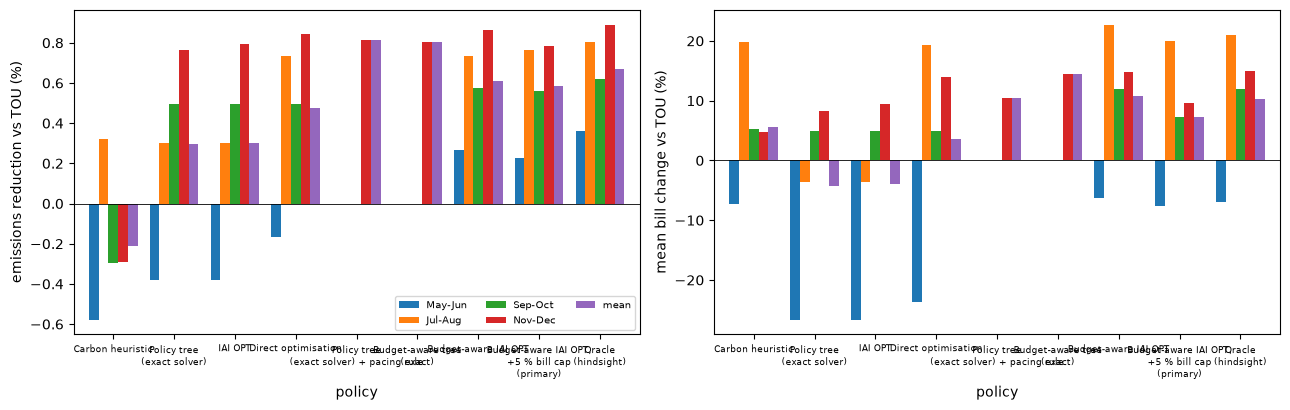

In [32]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.2))
show = [p for p in tab.index if p != "Historical TOU"]
for ax, t, lab in ((axes[0], tab, "emissions reduction vs TOU (%)"), (axes[1], bills, "mean bill change vs TOU (%)")):
    t.loc[show].plot.bar(ax=ax, width=0.8, legend=False); ax.axhline(0, color="k", lw=0.6); ax.set_ylabel(lab)
    ax.set_xticklabels([s.replace(" (", "\n(").replace(", +5", ",\n+5") for s in show], rotation=0, fontsize=6.5)
axes[0].legend(fontsize=7, ncol=3); plt.tight_layout(); plt.show()

**Findings (model-based).** (1) Demand-aware policies cut estimated emissions at a comparable average announced price, but
the effect is small (≈ 0.2–0.8 % over two months); the carbon-only heuristic raises emissions. (2) IAI and the exact solver
produce practically identical trees; for fixed trees the feasibility rule decides most days, and pacing only spreads the
events. (3) Remaining budget as a state feature makes the policy robust across windows. (4) The +5 % bill cap keeps most of
the reduction while lowering bills; the primary tree is mostly a one-split rule on the remaining budget — readable, but it
does not use the carbon forecast to time events.

## 9. Self-check

In [33]:
after = repo_hashes()
changed = sorted(k for k in set(BEFORE) | set(after) if BEFORE.get(k) != after.get(k))
print(f"{len(after)} repository files checked (size + modification time); changed by this notebook: {changed}")
assert not changed, "the notebook must not modify the repository"
print(f"finished in {time.time() - T0:.0f} s, mode {MODE!r}, windows trained live {WINDOWS}")

2678 repository files checked (size + modification time); changed by this notebook: []
finished in 19 s, mode 'review', windows trained live (11,)
